China A-share factor timing: final research experiment

We ask whether forecasts of Value, Profitability and Momentum can improve a long-short portfolio after costs. We keep the factor definitions fixed, as our professor advised. We compare fifteen models. We also test one rule that chooses a model every six months from its past portfolio returns.

We wrote the selection and comparison rules before running this extra experiment. We had already seen the 2025–2026 market results in M6, so this is a retrospective study. We report the earlier findings and this extra test separately. All models use the same completed monthly periods. The main test uses seed 42; four other seeds check training sensitivity.

In [1]:
from pathlib import Path
import logging
import warnings
import math
import hashlib
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.dates import AutoDateLocator, ConciseDateFormatter
import torch
from torch import nn
from prophet import Prophet
from cmdstanpy.utils import get_logger as get_cmdstanpy_logger
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from IPython.display import display
import json
import shutil


We use the saved prices, accounts and shares for our group of 100 companies. We use adjusted closes for return changes and raw A-share closes for company value. Every company is kept in the list, but a factor score needs the required data at that date.

In [2]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'inputs/china_factor_100').is_dir())
INPUTS = ROOT / 'inputs/china_factor_100'
RESULTS = ROOT / 'results/china_factor_timing_final'
RESULTS.mkdir(parents=True, exist_ok=True)
pd.options.display.float_format = '{:,.3f}'.format
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2})
get_cmdstanpy_logger().setLevel(logging.WARNING)
logging.getLogger('prophet').setLevel(logging.WARNING)

# Read the same saved inputs for every model.
companies = pd.read_csv(INPUTS / 'stocks.csv', dtype={'code': str})
price_rows = pd.read_csv(INPUTS / 'prices.csv', dtype={'code': str}, parse_dates=['date'])
financials = pd.read_csv(INPUTS / 'financials.csv', dtype={'code': str}, parse_dates=['period', 'notice_date', 'available_date'])
share_rows = pd.read_csv(INPUTS / 'shares.csv', dtype={'code': str}, parse_dates=['effective_date', 'notice_date', 'available_date'])
companies['is_financial'] = companies.is_financial.astype(str).str.lower().isin(['true', '1', 'yes'])
financials['usable'] = financials.usable.astype(str).str.lower().isin(['true', '1', 'yes'])
financials['balance_usable'] = financials.balance_usable.astype(str).str.lower().isin(['true', '1', 'yes'])
STOCKS = companies.code.tolist()
if len(STOCKS) != 100 or len(set(STOCKS)) != 100:
    raise ValueError('We need 100 different six-digit company codes.')
if not companies.code.str.fullmatch(r'[0-9]{6}').all():
    raise ValueError('Check the stock codes.')
if price_rows.duplicated(['code', 'date']).any():
    raise ValueError('A stock has more than one price on the same date.')
if not set(price_rows.code).issubset(STOCKS):
    raise ValueError('A price belongs to a company outside the list.')
calendar = pd.DatetimeIndex(pd.read_csv(ROOT / 'inputs/china_benchmark/market_calendar.csv', parse_dates=['date']).date)
calendar = calendar[(calendar >= price_rows.date.min()) & (calendar <= price_rows.date.max())]
price_rows = price_rows.loc[price_rows.date.isin(calendar)].copy()
observed = price_rows.pivot(index='date', columns='code', values='adjusted_close').reindex(index=calendar, columns=STOCKS)
raw_observed = price_rows.pivot(index='date', columns='code', values='raw_close').reindex(index=calendar, columns=STOCKS)
volumes = price_rows.pivot(index='date', columns='code', values='volume').reindex(index=calendar, columns=STOCKS)
observed = observed.where(observed.gt(0))
raw_observed = raw_observed.where(raw_observed.gt(0))
tradable = observed.notna() & raw_observed.notna() & volumes.gt(0)
# Carry a last price only for valuation. A trade still needs a fresh quote.
prices = observed.ffill()
raw_prices = raw_observed.ffill()
first_quote_dates = {}
for stock in STOCKS:
    first_quote_dates[stock] = observed[stock].first_valid_index()
first_quotes = pd.Series(first_quote_dates)
first_quotes.index.name = observed.columns.name
finance_by_code = {stock: rows.sort_values(['period', 'available_date']) for stock, rows in financials.groupby('code')}
shares_by_code = {stock: rows.sort_values(['effective_date', 'available_date']) for stock, rows in share_rows.groupby('code')}
company_info = companies.set_index('code')
daily_returns = prices.pct_change(fill_method=None)
if observed.stack().le(0).any():
    raise ValueError('Prices must be positive.')
source_files = pd.DataFrame([{'file': file.name, 'sha256': hashlib.sha256(file.read_bytes()).hexdigest()} for file in INPUTS.glob('*.csv')])
source_files.to_csv(RESULTS / 'input_files.csv', index=False)
companies.to_csv(RESULTS / 'companies.csv', index=False)
display(companies[['code', 'name_en', 'name_zh', 'listing_date', 'is_financial']])
FINAL_RESULTS = RESULTS
BASELINE = ROOT / 'results/china_factor_timing_m6'
SEEDS = [42, 7, 21, 84, 123]

input_record = []
for file in [INPUTS / name for name in ['stocks.csv', 'prices.csv', 'financials.csv', 'shares.csv']] + [ROOT / 'inputs/china_benchmark/market_calendar.csv']:
    input_record.append({'file': str(file.relative_to(ROOT)), 'sha256': hashlib.sha256(file.read_bytes()).hexdigest()})
pd.DataFrame(input_record).to_csv(RESULTS / 'input_files.csv', index=False)


,code,name_en,name_zh,listing_date,is_financial
0,002371,"NAURA Technology Group Co.,Ltd.",北方華創,2010-03-16,False
1,002422,"Sichuan Kelun Pharmaceutical Co., Ltd.",科倫藥業,2010-06-03,False
2,601728,China Telecom Corporation Limited,中國電信,2021-08-20,False
3,600276,"Jiangsu Hengrui Pharmaceuticals Co.,Ltd.",恒瑞醫藥,2000-10-18,False
4,600519,"Kweichow Moutai Co.,Ltd.",貴州茅臺,2001-08-27,False
...,...,...,...,...,...
95,000338,"Weichai Power Co., Ltd.",濰柴動力,2007-04-30,False
96,688008,"Montage Technology Co., Ltd.",瀾起科技,2019-07-22,False
97,600150,China CSSC Holdings Limited,中國船舶,1998-05-20,False
98,601127,"Seres Group Co.,Ltd.",賽力斯,2016-06-15,False


We keep the factor definitions fixed. Value is EBIT divided by enterprise value. Profitability is EBIT divided by average invested capital. Momentum is the price return from twelve months ago to one month ago, divided by annual volatility. This leaves the last month out of the momentum return. Banks and insurance companies remain in our list, but they do not enter these EBIT baskets because their debt and capital have a different meaning.

In [3]:
FACTORS = ['Value', 'Profitability', 'Momentum']
MIN_ELIGIBLE = 12
MIN_QUOTE_COUNT = 160
STALE_REPORT_MONTHS = 18
TAIL_FRACTION = 0.30
SIDE_WEIGHT = 0.50

month_signals = calendar.to_series().groupby(calendar.to_period('M')).last()
month_signals = pd.DatetimeIndex(month_signals)
score_tables = {}
baskets = {}
all_score_rows = []
basket_rows = []
coverage_rows = []

for signal in month_signals:
    rows = []
    one_month = signal - pd.DateOffset(months=1)
    twelve_months = signal - pd.DateOffset(months=12)

    for stock in STOCKS:
        result = {
            'signal': signal,
            'code': stock,
            'eligible': False,
            'reason': '',
            'Value': np.nan,
            'Profitability': np.nan,
            'Momentum': np.nan,
        }

        if company_info.loc[stock, 'is_financial']:
            result['reason'] = 'Financial business'
        elif not bool(tradable.loc[signal, stock]):
            result['reason'] = 'No trading quote on the decision date'
        elif pd.isna(first_quotes[stock]) or first_quotes[stock] > twelve_months:
            result['reason'] = 'Less than twelve months of price history'
        else:
            accounts = finance_by_code.get(stock, pd.DataFrame())
            known_shares = shares_by_code.get(stock, pd.DataFrame())

            if len(accounts):
                accounts = accounts.loc[accounts.available_date.le(signal)]
                accounts = accounts.sort_values(['period', 'available_date'])
                accounts = accounts.drop_duplicates('period', keep='last')
            if len(known_shares):
                known_shares = known_shares.loc[
                    known_shares.available_date.le(signal)
                    & known_shares.effective_date.le(signal)
                ]

            if accounts.empty:
                result['reason'] = 'No available annual accounts'
            elif known_shares.empty:
                result['reason'] = 'No available total share count'
            else:
                current = accounts.iloc[-1]
                prior = accounts.loc[accounts.period.eq(current.period - pd.DateOffset(years=1))]

                if not bool(current.usable):
                    result['reason'] = 'Incomplete EBIT or capital fields'
                elif prior.empty or not bool(prior.iloc[-1].balance_usable):
                    result['reason'] = 'No complete opening capital'
                elif signal > current.period + pd.DateOffset(months=STALE_REPORT_MONTHS):
                    result['reason'] = 'Annual accounts are more than eighteen months old'
                else:
                    opening = prior.iloc[-1]
                    shares = known_shares.iloc[-1]
                    market_cap = float(raw_prices.loc[signal, stock]) * float(shares.total_shares)
                    enterprise_value = market_cap + current.interest_debt + current.minority_equity - current.cash
                    average_capital = (current.invested_capital + opening.invested_capital) / 2
                    history = daily_returns.loc[twelve_months:signal, stock].dropna()
                    quote_count = int(tradable.loc[twelve_months:signal, stock].sum())
                    volatility = history.std(ddof=1) * np.sqrt(252)
                    one_month_prices = prices.loc[:one_month, stock]
                    twelve_month_prices = prices.loc[:twelve_months, stock]
                    one_month_close = float(one_month_prices.iloc[-1]) if len(one_month_prices) else np.nan
                    twelve_month_close = float(twelve_month_prices.iloc[-1]) if len(twelve_month_prices) else np.nan
                    momentum = one_month_close / twelve_month_close - 1
                    values = [current.ebit, enterprise_value, average_capital, market_cap, volatility, momentum]

                    if not np.isfinite(values).all() or min(enterprise_value, average_capital, market_cap, volatility) <= 0:
                        result['reason'] = 'Invalid factor denominator'
                    elif quote_count < MIN_QUOTE_COUNT:
                        result['reason'] = 'Too few daily trading quotes for momentum'
                    else:
                        result.update({
                            'eligible': True,
                            'reason': 'Available',
                            'Value': current.ebit / enterprise_value,
                            'Profitability': current.ebit / average_capital,
                            'Momentum': momentum / volatility,
                            'period': current.period,
                            'available_date': current.available_date,
                            'opening_available_date': opening.available_date,
                            'share_available_date': shares.available_date,
                            'share_effective_date': shares.effective_date,
                            'ebit': current.ebit,
                            'enterprise_value': enterprise_value,
                            'average_capital': average_capital,
                            'market_cap': market_cap,
                            'volatility': volatility,
                        })

        rows.append(result)

    scores = pd.DataFrame(rows).set_index('code')
    all_score_rows.append(scores.reset_index())
    if len(scores) != 100 or set(scores.index) != set(STOCKS):
        raise ValueError('Every monthly table must contain all 100 companies.')
    eligible = scores.loc[scores.eligible].sort_index()

    if len(eligible) >= MIN_ELIGIBLE:
        score_tables[signal] = scores
        count = int(math.floor(len(eligible) * TAIL_FRACTION))
        weights = pd.DataFrame(0.0, index=STOCKS, columns=FACTORS)
        for factor in FACTORS:
            ranked = eligible[factor].sort_values(ascending=False, kind='stable')
            long_codes = ranked.head(count).index
            short_codes = ranked.tail(count).index
            if set(long_codes).intersection(short_codes):
                raise ValueError('The long and short sides overlap.')
            weights.loc[long_codes, factor] = SIDE_WEIGHT / count
            weights.loc[short_codes, factor] = -SIDE_WEIGHT / count
            if not np.isclose(weights[factor].sum(), 0) or not np.isclose(weights[factor].abs().sum(), 1):
                raise ValueError('Each basket must have zero net and one unit of gross exposure.')
            for code in long_codes:
                basket_rows.append({'signal': signal, 'factor': factor, 'code': code, 'side': 'Long', 'weight': weights.loc[code, factor]})
            for code in short_codes:
                basket_rows.append({'signal': signal, 'factor': factor, 'code': code, 'side': 'Short', 'weight': weights.loc[code, factor]})
        baskets[signal] = weights
        coverage_rows.append({'signal': signal, 'listed_companies': len(STOCKS), 'eligible_companies': len(eligible), 'long_count': count, 'short_count': count, 'eligible_not_held_per_factor': len(eligible) - 2 * count, 'excluded_companies': len(STOCKS) - len(eligible)})

score_history = pd.concat(all_score_rows, ignore_index=True)
score_history.to_csv(RESULTS / 'factor_scores.csv', index=False)
eligible_counts = score_history.groupby('signal').eligible.sum().rename('eligible_count')
eligible_counts.to_csv(RESULTS / 'eligible_counts.csv')
pd.DataFrame(basket_rows).to_csv(RESULTS / 'factor_baskets.csv', index=False)
monthly_coverage = pd.DataFrame(coverage_rows).set_index('signal')
monthly_coverage.to_csv(RESULTS / 'monthly_coverage.csv')
exclusion_reasons = score_history.loc[~score_history.eligible].groupby(['signal', 'reason']).size().rename('companies').reset_index()
exclusion_reasons.to_csv(RESULTS / 'exclusion_reasons.csv', index=False)

if not baskets:
    raise ValueError('No month has enough complete company data.')

used = score_history.loc[score_history.eligible]
for field in ['available_date', 'opening_available_date', 'share_available_date', 'share_effective_date']:
    if not used[field].le(used.signal).all():
        raise ValueError('A factor score uses information from after its decision date.')

display(monthly_coverage.tail(6))
display(score_tables[max(score_tables)].query('eligible')[FACTORS].head(10))


,listed_companies,eligible_companies,long_count,short_count,eligible_not_held_per_factor,excluded_companies
signal,,,,,,
2026-05-29,100,93,27,27,39,7
2026-06-30,100,94,28,28,38,6
2026-07-31,100,94,28,28,38,6
2026-08-31,100,94,28,28,38,6
2026-09-30,100,94,28,28,38,6
2026-10-16,100,94,28,28,38,6


,Value,Profitability,Momentum
code,,,
002371,0.014,0.180,1.245
002422,0.038,0.093,0.374
601728,0.077,0.107,-0.197
600276,0.032,0.412,-1.071
600519,0.070,0.539,-0.544
688981,0.010,0.038,-0.095
300760,0.051,0.387,-1.172
688271,0.024,0.136,-1.029
688111,0.018,0.171,-0.614


For each factor, we buy the top 30% and short the bottom 30% of companies with valid scores. We round each group down to a whole number. The long side is +50% of the basket value and the short side is -50%. Companies have equal weights within each side. All three factors use the same eligible group each month. The basket returns used as model targets do not include trading fees or borrowing costs. We include these costs later when we compare the allocation rules.

In [4]:
INITIAL_VALUE = 100000.0
LONG_SHARE = 0.50
SHORT_SHARE = 0.50

entries = {}
for signal in score_tables:
    position = calendar.searchsorted(signal, side='right')
    if position < len(calendar):
        entries[signal] = calendar[position]

first_entry = min(entries.values())
first_position = calendar.get_loc(first_entry)
base_date = calendar[first_position - 1] if first_position > 0 else first_entry
factor_dates = calendar[(calendar >= base_date) & (calendar <= calendar[-1])]
factor_curves = {}
factor_exposure_rows = []

for factor in FACTORS:
    schedule = {}
    for signal, entry in entries.items():
        schedule[entry] = baskets[signal][factor].reindex(STOCKS, fill_value=0).to_numpy(float)

    holdings = np.zeros(len(STOCKS))
    cash = INITIAL_VALUE
    values = []
    previous = None

    for day in factor_dates:
        if previous is not None:
            relative = prices.loc[day].to_numpy(float) / prices.loc[previous].to_numpy(float)
            if not np.isfinite(relative[np.abs(holdings) > 1e-10]).all():
                raise ValueError('A held stock has no valuation price.')
            holdings *= np.where(np.isfinite(relative), relative, 1.0)

        before = cash + holdings.sum()
        if before <= 0 or not np.isfinite(before):
            raise ValueError('A factor basket has no positive capital left.')

        if day in schedule:
            target = schedule[day]
            can_trade = tradable.loc[day].to_numpy(bool)
            frozen = holdings[~can_trade]
            frozen_long = frozen[frozen > 0].sum()
            frozen_short = -frozen[frozen < 0].sum()
            long_budget = max(LONG_SHARE * before - frozen_long, 0.0)
            short_budget = max(SHORT_SHARE * before - frozen_short, 0.0)
            long_target = np.clip(target[can_trade], 0, None)
            short_target = np.clip(-target[can_trade], 0, None)

            # A suspended holding stays in place until it can trade again.
            holdings[can_trade] = 0.0
            if long_target.sum() > 0:
                holdings[can_trade] += long_budget * long_target / long_target.sum()
            if short_target.sum() > 0:
                holdings[can_trade] -= short_budget * short_target / short_target.sum()
            cash = before - holdings.sum()

            long_value = holdings[holdings > 0].sum()
            short_value = -holdings[holdings < 0].sum()
            balanced = np.isclose(long_value, LONG_SHARE * before) and np.isclose(short_value, SHORT_SHARE * before)
            if frozen_long <= LONG_SHARE * before and frozen_short <= SHORT_SHARE * before and long_target.sum() > 0 and short_target.sum() > 0 and not balanced:
                raise ValueError('The two sides do not match their planned exposure.')
            factor_exposure_rows.append({
                'factor': factor, 'date': day, 'value': before,
                'long_exposure': long_value / before,
                'short_exposure': -short_value / before,
                'gross_exposure': (long_value + short_value) / before,
                'net_exposure': (long_value - short_value) / before,
                'frozen_long': frozen_long / before,
                'frozen_short': frozen_short / before,
                'unavailable_long_targets': int(((target > 0) & ~can_trade).sum()),
                'unavailable_short_targets': int(((target < 0) & ~can_trade).sum()),
                'balanced': balanced,
            })

        value = cash + holdings.sum()
        if value <= 0 or not np.isfinite(value):
            raise ValueError('The factor value is invalid.')
        values.append({'date': day, 'value': value, 'cash': cash})
        previous = day

    curve = pd.DataFrame(values).set_index('date')
    factor_curves[factor] = curve.value

factor_values = pd.DataFrame(factor_curves)
factor_values.to_csv(RESULTS / 'factor_history.csv')
factor_exposure = pd.DataFrame(factor_exposure_rows)
factor_exposure.to_csv(RESULTS / 'factor_exposures.csv', index=False)

monthly_rows = []
signals = sorted(entries)
for signal, following in zip(signals[:-1], signals[1:]):
    if following.to_period('M') != signal.to_period('M') + 1:
        continue
    entry = entries[signal]
    exit_date = entries[following]
    outcome = factor_values.loc[exit_date] / factor_values.loc[entry] - 1
    monthly_rows.append({'signal': signal, 'entry': entry, 'exit': exit_date, **outcome.to_dict()})

factor_targets = pd.DataFrame(monthly_rows).set_index('signal')
factor_targets.to_csv(RESULTS / 'factor_targets.csv')
display(factor_targets.tail(6))
display(factor_exposure.groupby('factor')[['gross_exposure', 'net_exposure']].agg(['min', 'max']))


,entry,exit,Value,Profitability,Momentum
signal,,,,,
2026-03-31,2026-04-01,2026-05-06,-0.087,0.017,0.079
2026-04-30,2026-05-06,2026-06-01,-0.016,0.030,-0.001
2026-05-29,2026-06-01,2026-07-01,-0.086,0.018,0.023
2026-06-30,2026-07-01,2026-08-03,0.131,-0.008,-0.102
2026-07-31,2026-08-03,2026-09-01,-0.012,0.008,0.023
2026-08-31,2026-09-01,2026-10-08,0.023,-0.012,-0.023


gross_exposure       net_exposure      
                         min   max          min   max
factor                                               
Momentum               1.000 1.000       -0.000 0.000
Profitability          1.000 1.000       -0.000 0.000
Value                  1.000 1.000       -0.000 0.000

We decide after the last trading close of the month and trade at the next trading close. The long-short basket is a research simulation. It assumes that selected short positions can be borrowed. A missing quote does not create a trade. We keep an existing position at its last available price until a new quote arrives, and record any exposure difference caused by this rule. Cash earns zero interest in this test.

In [5]:
LOOKBACK = 8
RETURN_WINDOWS = (1, 4, 13)
RISK_WINDOW = 13
MIN_TRAINING = 36
VALIDATION_START = pd.Timestamp('2023-01-01')
VALIDATION_END = pd.Timestamp('2024-12-31')
TEST_START = pd.Timestamp('2025-01-01')
TEST_END = pd.Timestamp('2026-10-08')

sequences = {}
sequence_rows = []
sequence_date_rows = []

for signal in factor_targets.index:
    history = factor_values.loc[:signal]
    weekly = history.groupby(history.index.to_period('W-FRI')).tail(1)
    if len(weekly) < LOOKBACK + max(max(RETURN_WINDOWS), RISK_WINDOW):
        continue

    changes = weekly.pct_change(fill_method=None)
    rows = []
    for index in range(len(weekly) - LOOKBACK, len(weekly)):
        values = {}
        risk_returns = changes.iloc[index - RISK_WINDOW + 1:index + 1]
        for factor in FACTORS:
            for window in RETURN_WINDOWS:
                values[f'{factor}_{window}w'] = weekly[factor].iloc[index] / weekly[factor].iloc[index - window] - 1
            values[f'{factor}_volatility'] = risk_returns[factor].std(ddof=1) * np.sqrt(52)

        correlations = risk_returns.corr().to_numpy()[np.triu_indices(3, 1)]
        values['factor_correlation'] = float(correlations.mean())
        rows.append(values)

    frame = pd.DataFrame(rows, index=weekly.tail(LOOKBACK).index)
    if not np.isfinite(frame.to_numpy()).all():
        continue

    sequences[signal] = frame.to_numpy()
    sequence_rows.append(frame.assign(signal=signal).rename_axis('week').reset_index())
    sequence_date_rows.append({
        'signal': signal,
        'first_input_week': frame.index.min(),
        'last_input_week': frame.index.max(),
    })

sequence_dates = pd.DataFrame(sequence_date_rows).set_index('signal')
sample_signals = pd.DatetimeIndex(sorted(sequences))
samples = factor_targets.loc[sample_signals]
sample_x = np.stack([sequences[signal] for signal in sample_signals])
sample_y = samples[FACTORS].to_numpy()
pd.concat(sequence_rows, ignore_index=True).to_csv(RESULTS / 'sequence_inputs.csv', index=False)

validation_signals = samples.index[samples.entry.ge(VALIDATION_START) & samples.exit.le(VALIDATION_END)]
test_signals = samples.index[samples.entry.ge(TEST_START) & samples.exit.le(TEST_END)]
run_signals = samples.index[samples.entry.ge(VALIDATION_START) & samples.exit.le(TEST_END)]
if len(run_signals) != 45 or pd.Timestamp('2024-11-29') not in run_signals:
    raise ValueError('The continuous forecast history needs 45 periods, including the split boundary.')

if len(validation_signals) != 23 or len(test_signals) != 21:
    raise ValueError('We need 23 validation months and 21 completed evaluation months.')
if samples.loc[validation_signals].exit.max() > test_signals.min():
    raise ValueError('Model selection finishes after the first evaluation decision.')
for signal in run_signals:
    count = int(samples.exit.le(signal).sum())
    if count < MIN_TRAINING:
        raise ValueError(f'Only {count} completed training months before {signal.date()}.')

period_table = pd.DataFrame([
    {
        'part': 'Validation',
        'first_entry': samples.loc[validation_signals].entry.min(),
        'last_exit': samples.loc[validation_signals].exit.max(),
        'months': len(validation_signals),
    },
    {
        'part': 'Evaluation',
        'first_entry': samples.loc[test_signals].entry.min(),
        'last_exit': samples.loc[test_signals].exit.max(),
        'months': len(test_signals),
    },
])
period_table.to_csv(RESULTS / 'periods.csv', index=False)
display(period_table)
display(monthly_coverage.loc[run_signals].agg(['min', 'max']))
if not sequence_dates.last_input_week.le(sequence_dates.index).all():
    raise ValueError('An input uses a week after the forecast decision.')
sequence_dates.to_csv(RESULTS / 'sequence_dates.csv')


,part,first_entry,last_exit,months
0,Validation,2023-01-03,2024-12-02,23
1,Evaluation,2025-01-02,2026-10-08,21


,listed_companies,eligible_companies,long_count,short_count,eligible_not_held_per_factor,excluded_companies
min,100,90,27,27,36,6
max,100,94,28,28,39,10


Our factor trading starts on 1 August 2018. The model inputs use eight observed weeks. Each week includes factor returns over one, four and thirteen weeks, thirteen-week volatility and factor co-movement. We fit only on completed outcomes. We do not shuffle the dates because a forecast must use information that was already available. A fixed seed makes the main run repeatable. Other seeds check how much random training changes the result.

We forecast 45 monthly periods for a continuous shadow history. This includes the period from 2 December 2024 to 2 January 2025, which crosses the earlier validation boundary. That unfinished return is excluded from the first model-selection decision. The evaluation still has 21 periods from 2 January 2025 to 8 October 2026.

In [6]:
LEARNED_MODELS = ['Ridge', 'Elastic Net', 'KNN', 'SVR', 'Random Forest', 'Extra Trees', 'XGBoost', 'Decision Tree', 'AdaBoost', 'LightGBM', 'MLP', 'LSTM', 'GRU', 'CNN', 'Prophet']
MODEL_FILES = RESULTS / 'model_outputs'
MODEL_FILES.mkdir(parents=True, exist_ok=True)
model_audits = []
history_rows = []
training_rows = []

for signal in run_signals:
    training_mask = samples.exit.le(signal).to_numpy()
    training_index = sample_signals[training_mask]
    position = sample_signals.get_loc(signal)
    split = 'validation' if signal in validation_signals else ('evaluation' if signal in test_signals else 'bridge')
    if len(training_index) < MIN_TRAINING:
        raise ValueError('Too few completed training months.')
    forecast = sample_y[training_mask].mean(axis=0)
    training_rows.append({
        'signal': signal,
        'split': split,
        'training_months': len(training_index),
        'first_training_signal': training_index[0],
        'last_training_exit': samples.loc[training_index, 'exit'].max(),
        'first_input_week': sequence_dates.loc[signal, 'first_input_week'],
        'last_input_week': sequence_dates.loc[signal, 'last_input_week'],
    })
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        history_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'Historical mean', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

history_predictions = pd.DataFrame(history_rows)
training_audit = pd.DataFrame(training_rows)
training_audit.to_csv(RESULTS / 'training_dates.csv', index=False)
if not training_audit.last_training_exit.le(training_audit.signal).all():
    raise ValueError('Training includes a return that was not finished.')
if not training_audit.last_input_week.le(training_audit.signal).all():
    raise ValueError('Inputs include a future date.')
print('Historical mean:', len(history_predictions) // 3, 'monthly forecasts')
history_predictions.to_csv(MODEL_FILES / 'historical_mean_predictions.csv', index=False)
history_audit = training_audit.assign(model='Historical mean')
history_audit.to_csv(MODEL_FILES / 'historical_mean_audit.csv', index=False)
model_audits.append(history_audit)

prediction_frames = [history_predictions.assign(seed=42)]
model_audits = [history_audit.assign(seed=42)]


Historical mean: 45 monthly forecasts


Ridge is our linear model. Its penalty reduces large coefficients.

In [7]:
model_seeds = [42]
for run_seed in model_seeds:
    MODEL_FILES = RESULTS / 'model_outputs' / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    alpha = 10.0
    ridge_rows = []
    ridge_warnings = []

    for signal in run_signals:
        # Only completed past returns enter this fit.
        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position:position + 1].reshape(1, -1)
        split = 'validation' if signal in validation_signals else ('evaluation' if signal in test_signals else 'bridge')
        feature_scaler = StandardScaler().fit(train_x)
        target_scaler = StandardScaler().fit(train_y)
        fitting_x = feature_scaler.transform(train_x)
        fitting_y = target_scaler.transform(train_y)
        prediction_x = feature_scaler.transform(test_x)
        model = Ridge(alpha=alpha)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            ridge_warnings.append({'signal': signal, 'model': 'Ridge', 'message': str(warning.message)})
        forecast = target_scaler.inverse_transform(forecast)
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError('Ridge produced an invalid forecast.')
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            ridge_rows.append({
                'signal': signal, 'entry': samples.loc[signal, 'entry'],
                'exit': samples.loc[signal, 'exit'], 'split': split,
                'model': 'Ridge', 'factor': factor,
                'predicted_return': value, 'actual_return': actual,
            })

    ridge_predictions = pd.DataFrame(ridge_rows)
    print('Ridge:', len(ridge_predictions) // 3, 'monthly forecasts')
    ridge_predictions.to_csv(MODEL_FILES / 'ridge_predictions.csv', index=False)
    pd.DataFrame(ridge_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'ridge_warnings.csv', index=False)
    ridge_audit = training_audit.assign(model='Ridge')
    ridge_audit.to_csv(MODEL_FILES / 'ridge_audit.csv', index=False)
    model_audits.append(ridge_audit.assign(seed=run_seed))

    prediction_frames.append(ridge_predictions.assign(seed=run_seed))


Ridge: 45 monthly forecasts


Elastic Net is a linear model with two penalties. It can reduce some coefficients to zero.

In [8]:
model_seeds = [42]
for run_seed in model_seeds:
    MODEL_FILES = RESULTS / 'model_outputs' / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    alpha = 0.02
    l1_ratio = 0.5
    max_iterations = 10000
    seed = run_seed
    elastic_net_rows = []
    elastic_net_warnings = []

    for signal in run_signals:
        # Only completed past returns enter this fit.
        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position:position + 1].reshape(1, -1)
        split = 'validation' if signal in validation_signals else ('evaluation' if signal in test_signals else 'bridge')
        feature_scaler = StandardScaler().fit(train_x)
        target_scaler = StandardScaler().fit(train_y)
        fitting_x = feature_scaler.transform(train_x)
        fitting_y = target_scaler.transform(train_y)
        prediction_x = feature_scaler.transform(test_x)
        model = MultiOutputRegressor(ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=max_iterations, random_state=seed))
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            elastic_net_warnings.append({'signal': signal, 'model': 'Elastic Net', 'message': str(warning.message)})
        forecast = target_scaler.inverse_transform(forecast)
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError('Elastic Net produced an invalid forecast.')
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            elastic_net_rows.append({
                'signal': signal, 'entry': samples.loc[signal, 'entry'],
                'exit': samples.loc[signal, 'exit'], 'split': split,
                'model': 'Elastic Net', 'factor': factor,
                'predicted_return': value, 'actual_return': actual,
            })

    elastic_net_predictions = pd.DataFrame(elastic_net_rows)
    print('Elastic Net:', len(elastic_net_predictions) // 3, 'monthly forecasts')
    elastic_net_predictions.to_csv(MODEL_FILES / 'elastic_net_predictions.csv', index=False)
    pd.DataFrame(elastic_net_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'elastic_net_warnings.csv', index=False)
    elastic_net_audit = training_audit.assign(model='Elastic Net')
    elastic_net_audit.to_csv(MODEL_FILES / 'elastic_net_audit.csv', index=False)
    model_audits.append(elastic_net_audit.assign(seed=run_seed))

    prediction_frames.append(elastic_net_predictions.assign(seed=run_seed))


Elastic Net: 45 monthly forecasts


KNN uses twenty similar past samples to make a forecast.

In [9]:
model_seeds = [42]
for run_seed in model_seeds:
    MODEL_FILES = RESULTS / 'model_outputs' / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    neighbours = 20
    knn_rows = []
    knn_warnings = []

    for signal in run_signals:
        # Only completed past returns enter this fit.
        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position:position + 1].reshape(1, -1)
        split = 'validation' if signal in validation_signals else ('evaluation' if signal in test_signals else 'bridge')
        feature_scaler = StandardScaler().fit(train_x)
        target_scaler = StandardScaler().fit(train_y)
        fitting_x = feature_scaler.transform(train_x)
        fitting_y = target_scaler.transform(train_y)
        prediction_x = feature_scaler.transform(test_x)
        model = KNeighborsRegressor(n_neighbors=neighbours)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            knn_warnings.append({'signal': signal, 'model': 'KNN', 'message': str(warning.message)})
        forecast = target_scaler.inverse_transform(forecast)
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError('KNN produced an invalid forecast.')
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            knn_rows.append({
                'signal': signal, 'entry': samples.loc[signal, 'entry'],
                'exit': samples.loc[signal, 'exit'], 'split': split,
                'model': 'KNN', 'factor': factor,
                'predicted_return': value, 'actual_return': actual,
            })

    knn_predictions = pd.DataFrame(knn_rows)
    print('KNN:', len(knn_predictions) // 3, 'monthly forecasts')
    knn_predictions.to_csv(MODEL_FILES / 'knn_predictions.csv', index=False)
    pd.DataFrame(knn_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'knn_warnings.csv', index=False)
    knn_audit = training_audit.assign(model='KNN')
    knn_audit.to_csv(MODEL_FILES / 'knn_audit.csv', index=False)
    model_audits.append(knn_audit.assign(seed=run_seed))

    prediction_frames.append(knn_predictions.assign(seed=run_seed))


KNN: 45 monthly forecasts


SVR uses an RBF kernel. We fit a separate model for each factor.

In [10]:
model_seeds = [42]
for run_seed in model_seeds:
    MODEL_FILES = RESULTS / 'model_outputs' / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    regularization = 1.0
    epsilon = 0.1
    svr_rows = []
    svr_warnings = []

    for signal in run_signals:
        # Only completed past returns enter this fit.
        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position:position + 1].reshape(1, -1)
        split = 'validation' if signal in validation_signals else ('evaluation' if signal in test_signals else 'bridge')
        feature_scaler = StandardScaler().fit(train_x)
        target_scaler = StandardScaler().fit(train_y)
        fitting_x = feature_scaler.transform(train_x)
        fitting_y = target_scaler.transform(train_y)
        prediction_x = feature_scaler.transform(test_x)
        model = MultiOutputRegressor(SVR(C=regularization, epsilon=epsilon, kernel='rbf'))
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            svr_warnings.append({'signal': signal, 'model': 'SVR', 'message': str(warning.message)})
        forecast = target_scaler.inverse_transform(forecast)
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError('SVR produced an invalid forecast.')
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            svr_rows.append({
                'signal': signal, 'entry': samples.loc[signal, 'entry'],
                'exit': samples.loc[signal, 'exit'], 'split': split,
                'model': 'SVR', 'factor': factor,
                'predicted_return': value, 'actual_return': actual,
            })

    svr_predictions = pd.DataFrame(svr_rows)
    print('SVR:', len(svr_predictions) // 3, 'monthly forecasts')
    svr_predictions.to_csv(MODEL_FILES / 'svr_predictions.csv', index=False)
    pd.DataFrame(svr_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'svr_warnings.csv', index=False)
    svr_audit = training_audit.assign(model='SVR')
    svr_audit.to_csv(MODEL_FILES / 'svr_audit.csv', index=False)
    model_audits.append(svr_audit.assign(seed=run_seed))

    prediction_frames.append(svr_predictions.assign(seed=run_seed))


SVR: 45 monthly forecasts


Random Forest averages 150 trees. The depth and minimum leaf size limit each tree.

In [11]:
model_seeds = SEEDS
for run_seed in model_seeds:
    MODEL_FILES = RESULTS / 'model_outputs' / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    trees = 150
    max_depth = 4
    min_leaf = 12
    seed = run_seed
    random_forest_rows = []
    random_forest_warnings = []

    for signal in run_signals:
        # Only completed past returns enter this fit.
        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position:position + 1].reshape(1, -1)
        split = 'validation' if signal in validation_signals else ('evaluation' if signal in test_signals else 'bridge')
        fitting_x = train_x
        fitting_y = train_y
        prediction_x = test_x
        model = RandomForestRegressor(n_estimators=trees, max_depth=max_depth, min_samples_leaf=min_leaf, random_state=seed, n_jobs=2)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            random_forest_warnings.append({'signal': signal, 'model': 'Random Forest', 'message': str(warning.message)})
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError('Random Forest produced an invalid forecast.')
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            random_forest_rows.append({
                'signal': signal, 'entry': samples.loc[signal, 'entry'],
                'exit': samples.loc[signal, 'exit'], 'split': split,
                'model': 'Random Forest', 'factor': factor,
                'predicted_return': value, 'actual_return': actual,
            })

    random_forest_predictions = pd.DataFrame(random_forest_rows)
    print('Random Forest:', len(random_forest_predictions) // 3, 'monthly forecasts')
    random_forest_predictions.to_csv(MODEL_FILES / 'random_forest_predictions.csv', index=False)
    pd.DataFrame(random_forest_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'random_forest_warnings.csv', index=False)
    random_forest_audit = training_audit.assign(model='Random Forest')
    random_forest_audit.to_csv(MODEL_FILES / 'random_forest_audit.csv', index=False)
    model_audits.append(random_forest_audit.assign(seed=run_seed))

    prediction_frames.append(random_forest_predictions.assign(seed=run_seed))


Random Forest: 45 monthly forecasts


Random Forest: 45 monthly forecasts


Random Forest: 45 monthly forecasts


Random Forest: 45 monthly forecasts


Random Forest: 45 monthly forecasts


Extra Trees also averages trees. It makes more random choices when it divides the inputs.

In [12]:
model_seeds = SEEDS
for run_seed in model_seeds:
    MODEL_FILES = RESULTS / 'model_outputs' / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    trees = 150
    max_depth = 4
    min_leaf = 12
    seed = run_seed
    extra_trees_rows = []
    extra_trees_warnings = []

    for signal in run_signals:
        # Only completed past returns enter this fit.
        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position:position + 1].reshape(1, -1)
        split = 'validation' if signal in validation_signals else ('evaluation' if signal in test_signals else 'bridge')
        fitting_x = train_x
        fitting_y = train_y
        prediction_x = test_x
        model = ExtraTreesRegressor(n_estimators=trees, max_depth=max_depth, min_samples_leaf=min_leaf, random_state=seed, n_jobs=2)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            extra_trees_warnings.append({'signal': signal, 'model': 'Extra Trees', 'message': str(warning.message)})
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError('Extra Trees produced an invalid forecast.')
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            extra_trees_rows.append({
                'signal': signal, 'entry': samples.loc[signal, 'entry'],
                'exit': samples.loc[signal, 'exit'], 'split': split,
                'model': 'Extra Trees', 'factor': factor,
                'predicted_return': value, 'actual_return': actual,
            })

    extra_trees_predictions = pd.DataFrame(extra_trees_rows)
    print('Extra Trees:', len(extra_trees_predictions) // 3, 'monthly forecasts')
    extra_trees_predictions.to_csv(MODEL_FILES / 'extra_trees_predictions.csv', index=False)
    pd.DataFrame(extra_trees_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'extra_trees_warnings.csv', index=False)
    extra_trees_audit = training_audit.assign(model='Extra Trees')
    extra_trees_audit.to_csv(MODEL_FILES / 'extra_trees_audit.csv', index=False)
    model_audits.append(extra_trees_audit.assign(seed=run_seed))

    prediction_frames.append(extra_trees_predictions.assign(seed=run_seed))


Extra Trees: 45 monthly forecasts


Extra Trees: 45 monthly forecasts


Extra Trees: 45 monthly forecasts


Extra Trees: 45 monthly forecasts


Extra Trees: 45 monthly forecasts


XGBoost adds small trees one after another. Each new tree tries to reduce the remaining error.

In [13]:
model_seeds = SEEDS
for run_seed in model_seeds:
    MODEL_FILES = RESULTS / 'model_outputs' / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    trees = 120
    max_depth = 2
    learning_rate = 0.03
    subsample = 0.8
    column_sample = 0.9
    l2_penalty = 5.0
    seed = run_seed
    xgboost_rows = []
    xgboost_warnings = []

    for signal in run_signals:
        # Only completed past returns enter this fit.
        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position:position + 1].reshape(1, -1)
        split = 'validation' if signal in validation_signals else ('evaluation' if signal in test_signals else 'bridge')
        fitting_x = train_x
        fitting_y = train_y
        prediction_x = test_x
        model = MultiOutputRegressor(XGBRegressor(n_estimators=trees, max_depth=max_depth, learning_rate=learning_rate, subsample=subsample, colsample_bytree=column_sample, reg_lambda=l2_penalty, objective='reg:squarederror', random_state=seed, n_jobs=2))
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            xgboost_warnings.append({'signal': signal, 'model': 'XGBoost', 'message': str(warning.message)})
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError('XGBoost produced an invalid forecast.')
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            xgboost_rows.append({
                'signal': signal, 'entry': samples.loc[signal, 'entry'],
                'exit': samples.loc[signal, 'exit'], 'split': split,
                'model': 'XGBoost', 'factor': factor,
                'predicted_return': value, 'actual_return': actual,
            })

    xgboost_predictions = pd.DataFrame(xgboost_rows)
    print('XGBoost:', len(xgboost_predictions) // 3, 'monthly forecasts')
    xgboost_predictions.to_csv(MODEL_FILES / 'xgboost_predictions.csv', index=False)
    pd.DataFrame(xgboost_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'xgboost_warnings.csv', index=False)
    xgboost_audit = training_audit.assign(model='XGBoost')
    xgboost_audit.to_csv(MODEL_FILES / 'xgboost_audit.csv', index=False)
    model_audits.append(xgboost_audit.assign(seed=run_seed))

    prediction_frames.append(xgboost_predictions.assign(seed=run_seed))


XGBoost: 45 monthly forecasts


XGBoost: 45 monthly forecasts


XGBoost: 45 monthly forecasts


XGBoost: 45 monthly forecasts


XGBoost: 45 monthly forecasts


We use one decision tree to predict the three factor returns. We limit its depth to three and keep at least twelve training months in each leaf. This gives us a basic tree model to compare with the groups of trees.

In [14]:
model_seeds = SEEDS
for run_seed in model_seeds:
    MODEL_FILES = RESULTS / 'model_outputs' / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    max_depth = 3
    min_leaf = 12
    seed = run_seed
    decision_tree_rows = []
    decision_tree_warnings = []

    for signal in run_signals:
        # Only completed past returns enter this fit.
        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position:position + 1].reshape(1, -1)
        split = 'validation' if signal in validation_signals else ('evaluation' if signal in test_signals else 'bridge')
        fitting_x = train_x
        fitting_y = train_y
        prediction_x = test_x
        model = DecisionTreeRegressor(max_depth=max_depth, min_samples_leaf=min_leaf, random_state=seed)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            decision_tree_warnings.append({'signal': signal, 'model': 'Decision Tree', 'message': str(warning.message)})
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError('Decision Tree produced an invalid forecast.')
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            decision_tree_rows.append({
                'signal': signal, 'entry': samples.loc[signal, 'entry'],
                'exit': samples.loc[signal, 'exit'], 'split': split,
                'model': 'Decision Tree', 'factor': factor,
                'predicted_return': value, 'actual_return': actual,
            })

    decision_tree_predictions = pd.DataFrame(decision_tree_rows)
    print('Decision Tree:', len(decision_tree_predictions) // 3, 'monthly forecasts')
    decision_tree_predictions.to_csv(MODEL_FILES / 'decision_tree_predictions.csv', index=False)
    pd.DataFrame(decision_tree_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'decision_tree_warnings.csv', index=False)
    decision_tree_audit = training_audit.assign(model='Decision Tree')
    decision_tree_audit.to_csv(MODEL_FILES / 'decision_tree_audit.csv', index=False)
    model_audits.append(decision_tree_audit.assign(seed=run_seed))

    prediction_frames.append(decision_tree_predictions.assign(seed=run_seed))


Decision Tree: 45 monthly forecasts
Decision Tree: 45 monthly forecasts


Decision Tree: 45 monthly forecasts


Decision Tree: 45 monthly forecasts
Decision Tree: 45 monthly forecasts


AdaBoost fits small trees one after another. It gives more weight to training months with larger errors. We fit one model for each factor, using the same completed months and settings.

In [15]:
model_seeds = SEEDS
for run_seed in model_seeds:
    MODEL_FILES = RESULTS / 'model_outputs' / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    trees = 100
    max_depth = 2
    min_leaf = 8
    learning_rate = 0.03
    loss = 'linear'
    seed = run_seed
    adaboost_rows = []
    adaboost_warnings = []

    for signal in run_signals:
        # Only completed past returns enter this fit.
        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position:position + 1].reshape(1, -1)
        split = 'validation' if signal in validation_signals else ('evaluation' if signal in test_signals else 'bridge')
        fitting_x = train_x
        fitting_y = train_y
        prediction_x = test_x
        base_tree = DecisionTreeRegressor(max_depth=max_depth, min_samples_leaf=min_leaf, random_state=seed)
        model = MultiOutputRegressor(AdaBoostRegressor(estimator=base_tree, n_estimators=trees, learning_rate=learning_rate, loss=loss, random_state=seed))
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            adaboost_warnings.append({'signal': signal, 'model': 'AdaBoost', 'message': str(warning.message)})
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError('AdaBoost produced an invalid forecast.')
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            adaboost_rows.append({
                'signal': signal, 'entry': samples.loc[signal, 'entry'],
                'exit': samples.loc[signal, 'exit'], 'split': split,
                'model': 'AdaBoost', 'factor': factor,
                'predicted_return': value, 'actual_return': actual,
            })

    adaboost_predictions = pd.DataFrame(adaboost_rows)
    print('AdaBoost:', len(adaboost_predictions) // 3, 'monthly forecasts')
    adaboost_predictions.to_csv(MODEL_FILES / 'adaboost_predictions.csv', index=False)
    pd.DataFrame(adaboost_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'adaboost_warnings.csv', index=False)
    adaboost_audit = training_audit.assign(model='AdaBoost')
    adaboost_audit.to_csv(MODEL_FILES / 'adaboost_audit.csv', index=False)
    model_audits.append(adaboost_audit.assign(seed=run_seed))

    prediction_frames.append(adaboost_predictions.assign(seed=run_seed))


AdaBoost: 45 monthly forecasts


AdaBoost: 45 monthly forecasts


AdaBoost: 45 monthly forecasts


AdaBoost: 45 monthly forecasts


AdaBoost: 45 monthly forecasts


LightGBM is another model that combines small trees. We use 120 trees with a maximum depth of two and four leaves. We fit one return model for each factor. The inputs and forecast months stay the same as in the other model cells.

In [16]:
model_seeds = SEEDS
for run_seed in model_seeds:
    MODEL_FILES = RESULTS / 'model_outputs' / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    trees = 120
    max_depth = 2
    leaves = 4
    min_leaf = 12
    learning_rate = 0.03
    l2_penalty = 5.0
    workers = 2
    seed = run_seed
    lightgbm_rows = []
    lightgbm_warnings = []

    for signal in run_signals:
        # Only completed past returns enter this fit.
        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position:position + 1].reshape(1, -1)
        split = 'validation' if signal in validation_signals else ('evaluation' if signal in test_signals else 'bridge')
        input_names = [f'input_{number}' for number in range(train_x.shape[1])]
        fitting_x = pd.DataFrame(train_x, columns=input_names)
        fitting_y = train_y
        prediction_x = pd.DataFrame(test_x, columns=input_names)
        model = MultiOutputRegressor(LGBMRegressor(
            n_estimators=trees, max_depth=max_depth, num_leaves=leaves,
            min_child_samples=min_leaf, learning_rate=learning_rate,
            reg_lambda=l2_penalty, random_state=seed, n_jobs=workers,
            deterministic=True, force_col_wise=True, verbosity=-1,
        ))
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            lightgbm_warnings.append({'signal': signal, 'model': 'LightGBM', 'message': str(warning.message)})
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError('LightGBM produced an invalid forecast.')
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            lightgbm_rows.append({
                'signal': signal, 'entry': samples.loc[signal, 'entry'],
                'exit': samples.loc[signal, 'exit'], 'split': split,
                'model': 'LightGBM', 'factor': factor,
                'predicted_return': value, 'actual_return': actual,
            })

    lightgbm_predictions = pd.DataFrame(lightgbm_rows)
    print('LightGBM:', len(lightgbm_predictions) // 3, 'monthly forecasts')
    lightgbm_predictions.to_csv(MODEL_FILES / 'lightgbm_predictions.csv', index=False)
    pd.DataFrame(lightgbm_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'lightgbm_warnings.csv', index=False)
    lightgbm_audit = training_audit.assign(model='LightGBM')
    lightgbm_audit.to_csv(MODEL_FILES / 'lightgbm_audit.csv', index=False)
    model_audits.append(lightgbm_audit.assign(seed=run_seed))

    prediction_frames.append(lightgbm_predictions.assign(seed=run_seed))


LightGBM: 45 monthly forecasts


LightGBM: 45 monthly forecasts


LightGBM: 45 monthly forecasts


LightGBM: 45 monthly forecasts


LightGBM: 45 monthly forecasts


The MLP is a neural network with one hidden layer of twelve units. It reads the eight weeks as one row of inputs.

In [17]:
model_seeds = SEEDS
for run_seed in model_seeds:
    MODEL_FILES = RESULTS / 'model_outputs' / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    hidden_units = (12,)
    alpha = 5.0
    max_iterations = 1500
    max_function_calls = 30000
    tolerance = 0.0001
    seed = run_seed
    mlp_rows = []
    mlp_warnings = []

    for signal in run_signals:
        # Only completed past returns enter this fit.
        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position:position + 1].reshape(1, -1)
        split = 'validation' if signal in validation_signals else ('evaluation' if signal in test_signals else 'bridge')
        feature_scaler = StandardScaler().fit(train_x)
        target_scaler = StandardScaler().fit(train_y)
        fitting_x = feature_scaler.transform(train_x)
        fitting_y = target_scaler.transform(train_y)
        prediction_x = feature_scaler.transform(test_x)
        model = MLPRegressor(hidden_layer_sizes=hidden_units, solver='lbfgs', alpha=alpha, max_iter=max_iterations, max_fun=max_function_calls, tol=tolerance, random_state=seed)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            mlp_warnings.append({'signal': signal, 'model': 'MLP', 'message': str(warning.message)})
        forecast = target_scaler.inverse_transform(forecast)
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError('MLP produced an invalid forecast.')
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            mlp_rows.append({
                'signal': signal, 'entry': samples.loc[signal, 'entry'],
                'exit': samples.loc[signal, 'exit'], 'split': split,
                'model': 'MLP', 'factor': factor,
                'predicted_return': value, 'actual_return': actual,
            })

    mlp_predictions = pd.DataFrame(mlp_rows)
    print('MLP:', len(mlp_predictions) // 3, 'monthly forecasts')
    mlp_predictions.to_csv(MODEL_FILES / 'mlp_predictions.csv', index=False)
    pd.DataFrame(mlp_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'mlp_warnings.csv', index=False)
    mlp_audit = training_audit.assign(model='MLP')
    mlp_audit.to_csv(MODEL_FILES / 'mlp_audit.csv', index=False)
    model_audits.append(mlp_audit.assign(seed=run_seed))

    prediction_frames.append(mlp_predictions.assign(seed=run_seed))


MLP: 45 monthly forecasts


MLP: 45 monthly forecasts


MLP: 45 monthly forecasts


MLP: 45 monthly forecasts


MLP: 45 monthly forecasts


The LSTM reads the weekly inputs in time order. We use two LSTM layers with 32 hidden units. We train for up to 100 epochs and stop after ten epochs without enough improvement. The last 20% of the available training months guide early stopping. The earlier fitting returns finish before that internal check starts. Scaling is fitted only on the earlier fitting data. We restore the weights from the best epoch before making the forecast.

In [18]:
model_seeds = SEEDS
for run_seed in model_seeds:
    MODEL_FILES = RESULTS / 'model_outputs' / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    hidden_units = 32
    layers = 2
    dropout = 0.1
    max_epochs = 100
    patience = 10
    minimum_improvement = 0.0001
    validation_fraction = 0.2
    learning_rate = 0.001
    weight_decay = 0.01
    seed = run_seed
    lstm_rows = []
    lstm_training_rows = []
    lstm_epoch_rows = []
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)

    for signal in run_signals:
        torch.manual_seed(seed)
        training_mask = samples.exit.le(signal).to_numpy()
        training_index = sample_signals[training_mask]
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask]
        train_y = sample_y[training_mask]
        test_x = sample_x[position:position + 1]
        split = 'validation' if signal in validation_signals else ('evaluation' if signal in test_signals else 'bridge')

        validation_count = math.ceil(len(train_x) * validation_fraction)
        split_position = len(train_x) - validation_count
        validation_index = training_index[split_position:]
        fitting_index = training_index[:split_position]
        completed = samples.loc[fitting_index, 'exit'].le(validation_index[0]).to_numpy()
        fitting_index = fitting_index[completed]
        fitting_x = train_x[:split_position][completed]
        fitting_y = train_y[:split_position][completed]
        validation_x = train_x[split_position:]
        validation_y = train_y[split_position:]
        if len(fitting_x) < MIN_TRAINING:
            raise ValueError('Too few completed fitting months for the LSTM.')

        features = fitting_x.shape[-1]
        feature_scaler = StandardScaler().fit(fitting_x.reshape(-1, features))
        target_scaler = StandardScaler().fit(fitting_y)
        scaled_fit = feature_scaler.transform(fitting_x.reshape(-1, features)).reshape(fitting_x.shape)
        scaled_validation = feature_scaler.transform(validation_x.reshape(-1, features)).reshape(validation_x.shape)
        scaled_test = feature_scaler.transform(test_x.reshape(-1, features)).reshape(test_x.shape)
        inputs = torch.tensor(scaled_fit, dtype=torch.float32)
        targets = torch.tensor(target_scaler.transform(fitting_y), dtype=torch.float32)
        validation_inputs = torch.tensor(scaled_validation, dtype=torch.float32)
        validation_targets = torch.tensor(target_scaler.transform(validation_y), dtype=torch.float32)
        prediction_inputs = torch.tensor(scaled_test, dtype=torch.float32)

        lstm = nn.LSTM(input_size=features, hidden_size=hidden_units, num_layers=layers, dropout=dropout, batch_first=True)
        output_layer = nn.Linear(hidden_units, len(FACTORS))
        optimizer = torch.optim.Adam(list(lstm.parameters()) + list(output_layer.parameters()), lr=learning_rate, weight_decay=weight_decay)
        loss_function = nn.MSELoss()
        best_validation_loss = float('inf')
        best_epoch = 0
        waiting = 0
        training_losses = []
        validation_losses = []

        for epoch in range(1, max_epochs + 1):
            lstm.train()
            output_layer.train()
            optimizer.zero_grad()
            sequence_output, _ = lstm(inputs)
            fitted_returns = output_layer(sequence_output[:, -1, :])
            loss = loss_function(fitted_returns, targets)
            if not torch.isfinite(loss):
                raise ValueError('The LSTM fitting loss is not finite.')
            loss.backward()
            optimizer.step()

            lstm.eval()
            output_layer.eval()
            with torch.no_grad():
                validation_sequence, _ = lstm(validation_inputs)
                validation_returns = output_layer(validation_sequence[:, -1, :])
                validation_loss = loss_function(validation_returns, validation_targets).item()
            if not np.isfinite(validation_loss):
                raise ValueError('The LSTM validation loss is not finite.')
            training_losses.append(loss.item())
            validation_losses.append(validation_loss)
            lstm_epoch_rows.append({'signal': signal, 'split': split, 'epoch': epoch, 'training_loss': loss.item(), 'validation_loss': validation_loss})

            if validation_loss < best_validation_loss - minimum_improvement:
                best_validation_loss = validation_loss
                best_epoch = epoch
                best_lstm_weights = {name: value.detach().clone() for name, value in lstm.state_dict().items()}
                best_output_weights = {name: value.detach().clone() for name, value in output_layer.state_dict().items()}
                waiting = 0
            else:
                waiting += 1
            if waiting >= patience:
                break

        lstm.load_state_dict(best_lstm_weights)
        output_layer.load_state_dict(best_output_weights)
        lstm.eval()
        output_layer.eval()
        with torch.no_grad():
            prediction_sequence, _ = lstm(prediction_inputs)
            scaled_forecast = output_layer(prediction_sequence[:, -1, :]).numpy()
        forecast = target_scaler.inverse_transform(scaled_forecast)[0]
        if not np.isfinite(forecast).all():
            raise ValueError('LSTM produced an invalid forecast.')

        lstm_training_rows.append({
            'signal': signal, 'split': split, 'model': 'LSTM',
            'first_loss': training_losses[0], 'last_loss': training_losses[-1],
            'epochs_run': epoch, 'best_epoch': best_epoch,
            'best_validation_loss': best_validation_loss,
            'fit_months': len(fitting_index), 'internal_validation_months': len(validation_index),
            'fit_target_end': samples.loc[fitting_index, 'exit'].max(),
            'internal_validation_start': validation_index[0],
            'internal_validation_end': samples.loc[validation_index, 'exit'].max(),
        })
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            lstm_rows.append({
                'signal': signal, 'entry': samples.loc[signal, 'entry'],
                'exit': samples.loc[signal, 'exit'], 'split': split,
                'model': 'LSTM', 'factor': factor,
                'predicted_return': value, 'actual_return': actual,
            })

    lstm_predictions = pd.DataFrame(lstm_rows)
    lstm_training = pd.DataFrame(lstm_training_rows)
    if not lstm_training.fit_target_end.le(lstm_training.internal_validation_start).all():
        raise ValueError('LSTM fitting targets overlap the internal validation decisions.')
    if not lstm_training.internal_validation_end.le(lstm_training.signal).all():
        raise ValueError('LSTM early stopping uses a return from after the forecast date.')
    print('LSTM:', len(lstm_predictions) // 3, 'monthly forecasts')
    display(lstm_training[['signal', 'epochs_run', 'best_epoch', 'best_validation_loss']].tail())

    lstm_predictions.to_csv(MODEL_FILES / 'lstm_predictions.csv', index=False)
    lstm_training.to_csv(MODEL_FILES / 'lstm_training.csv', index=False)
    pd.DataFrame(lstm_epoch_rows).to_csv(MODEL_FILES / 'lstm_epoch_losses.csv', index=False)
    lstm_audit = training_audit.assign(model='LSTM').merge(lstm_training.drop(columns=['split', 'model']), on='signal', validate='one_to_one')
    lstm_audit.to_csv(MODEL_FILES / 'lstm_audit.csv', index=False)
    model_audits.append(lstm_audit.assign(seed=run_seed))

    prediction_frames.append(lstm_predictions.assign(seed=run_seed))


LSTM: 45 monthly forecasts


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,93,83,0.649
41,2026-05-29,11,1,0.725
42,2026-06-30,11,1,0.738
43,2026-07-31,11,1,0.797
44,2026-08-31,20,10,1.195


LSTM: 45 monthly forecasts


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,100,100,0.633
41,2026-05-29,100,100,0.675
42,2026-06-30,100,100,0.711
43,2026-07-31,79,69,0.827
44,2026-08-31,93,83,1.168


LSTM: 45 monthly forecasts


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,96,86,0.620
41,2026-05-29,17,7,0.711
42,2026-06-30,11,1,0.713
43,2026-07-31,11,1,0.783
44,2026-08-31,12,2,1.171


LSTM: 45 monthly forecasts


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,89,79,0.654
41,2026-05-29,96,86,0.686
42,2026-06-30,97,87,0.706
43,2026-07-31,97,87,0.812
44,2026-08-31,85,75,1.168


LSTM: 45 monthly forecasts


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,22,12,0.664
41,2026-05-29,100,100,0.665
42,2026-06-30,23,13,0.745
43,2026-07-31,25,15,0.822
44,2026-08-31,16,6,1.185


The GRU reads the weekly inputs in time order. We use two layers with 32 hidden units and one output for each factor. Training runs for up to 100 epochs. The last 20% of the available training months guide early stopping, with a patience of ten epochs. Earlier fitting returns finish before this internal check starts. We fit the scalers only on those earlier fitting data and restore the best saved weights before each forecast.

In [19]:
model_seeds = SEEDS
for run_seed in model_seeds:
    MODEL_FILES = RESULTS / 'model_outputs' / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    hidden_units = 32
    layers = 2
    dropout = 0.1
    max_epochs = 100
    patience = 10
    minimum_improvement = 0.0001
    validation_fraction = 0.2
    learning_rate = 0.001
    weight_decay = 0.01
    seed = run_seed
    gru_rows = []
    gru_training_rows = []
    gru_epoch_rows = []
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)

    for signal in run_signals:
        torch.manual_seed(seed)
        training_mask = samples.exit.le(signal).to_numpy()
        training_index = sample_signals[training_mask]
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask]
        train_y = sample_y[training_mask]
        test_x = sample_x[position:position + 1]
        split = 'validation' if signal in validation_signals else ('evaluation' if signal in test_signals else 'bridge')

        # Later training months guide early stopping.
        validation_count = math.ceil(len(train_x) * validation_fraction)
        split_position = len(train_x) - validation_count
        validation_index = training_index[split_position:]
        fitting_index = training_index[:split_position]
        completed = samples.loc[fitting_index, 'exit'].le(validation_index[0]).to_numpy()
        fitting_index = fitting_index[completed]
        fitting_x = train_x[:split_position][completed]
        fitting_y = train_y[:split_position][completed]
        validation_x = train_x[split_position:]
        validation_y = train_y[split_position:]
        if len(fitting_x) < MIN_TRAINING:
            raise ValueError('Too few completed fitting months for the GRU.')

        features = fitting_x.shape[-1]
        feature_scaler = StandardScaler().fit(fitting_x.reshape(-1, features))
        target_scaler = StandardScaler().fit(fitting_y)
        scaled_fit = feature_scaler.transform(fitting_x.reshape(-1, features)).reshape(fitting_x.shape)
        scaled_validation = feature_scaler.transform(validation_x.reshape(-1, features)).reshape(validation_x.shape)
        scaled_test = feature_scaler.transform(test_x.reshape(-1, features)).reshape(test_x.shape)
        inputs = torch.tensor(scaled_fit, dtype=torch.float32)
        targets = torch.tensor(target_scaler.transform(fitting_y), dtype=torch.float32)
        validation_inputs = torch.tensor(scaled_validation, dtype=torch.float32)
        validation_targets = torch.tensor(target_scaler.transform(validation_y), dtype=torch.float32)
        prediction_inputs = torch.tensor(scaled_test, dtype=torch.float32)

        gru = nn.GRU(input_size=features, hidden_size=hidden_units, num_layers=layers, dropout=dropout, batch_first=True)
        output_layer = nn.Linear(hidden_units, len(FACTORS))
        optimizer = torch.optim.Adam(list(gru.parameters()) + list(output_layer.parameters()), lr=learning_rate, weight_decay=weight_decay)
        loss_function = nn.MSELoss()
        best_validation_loss = float('inf')
        best_epoch = 0
        waiting = 0
        training_losses = []
        validation_losses = []

        for epoch in range(1, max_epochs + 1):
            gru.train()
            output_layer.train()
            optimizer.zero_grad()
            sequence_output, _ = gru(inputs)
            fitted_returns = output_layer(sequence_output[:, -1, :])
            loss = loss_function(fitted_returns, targets)
            if not torch.isfinite(loss):
                raise ValueError('The GRU fitting loss is not finite.')
            loss.backward()
            optimizer.step()

            gru.eval()
            output_layer.eval()
            with torch.no_grad():
                validation_sequence, _ = gru(validation_inputs)
                validation_returns = output_layer(validation_sequence[:, -1, :])
                validation_loss = loss_function(validation_returns, validation_targets).item()
            if not np.isfinite(validation_loss):
                raise ValueError('The GRU validation loss is not finite.')
            training_losses.append(loss.item())
            validation_losses.append(validation_loss)
            gru_epoch_rows.append({'signal': signal, 'split': split, 'epoch': epoch, 'training_loss': loss.item(), 'validation_loss': validation_loss})

            if validation_loss < best_validation_loss - minimum_improvement:
                best_validation_loss = validation_loss
                best_epoch = epoch
                best_gru_weights = {name: value.detach().clone() for name, value in gru.state_dict().items()}
                best_output_weights = {name: value.detach().clone() for name, value in output_layer.state_dict().items()}
                waiting = 0
            else:
                waiting += 1
            if waiting >= patience:
                break

        gru.load_state_dict(best_gru_weights)
        output_layer.load_state_dict(best_output_weights)
        gru.eval()
        output_layer.eval()
        with torch.no_grad():
            prediction_sequence, _ = gru(prediction_inputs)
            scaled_forecast = output_layer(prediction_sequence[:, -1, :]).numpy()
        forecast = target_scaler.inverse_transform(scaled_forecast)[0]
        if not np.isfinite(forecast).all():
            raise ValueError('GRU produced an invalid forecast.')

        gru_training_rows.append({
            'signal': signal, 'split': split, 'model': 'GRU',
            'first_loss': training_losses[0], 'last_loss': training_losses[-1],
            'epochs_run': epoch, 'best_epoch': best_epoch,
            'best_validation_loss': best_validation_loss,
            'fit_months': len(fitting_index), 'internal_validation_months': len(validation_index),
            'fit_target_end': samples.loc[fitting_index, 'exit'].max(),
            'internal_validation_start': validation_index[0],
            'internal_validation_end': samples.loc[validation_index, 'exit'].max(),
        })
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            gru_rows.append({
                'signal': signal, 'entry': samples.loc[signal, 'entry'],
                'exit': samples.loc[signal, 'exit'], 'split': split,
                'model': 'GRU', 'factor': factor,
                'predicted_return': value, 'actual_return': actual,
            })

    gru_predictions = pd.DataFrame(gru_rows)
    gru_training = pd.DataFrame(gru_training_rows)
    if not gru_training.fit_target_end.le(gru_training.internal_validation_start).all():
        raise ValueError('GRU fitting targets overlap the internal validation decisions.')
    if not gru_training.internal_validation_end.le(gru_training.signal).all():
        raise ValueError('GRU early stopping uses a return from after the forecast date.')
    print('GRU:', len(gru_predictions) // 3, 'monthly forecasts')
    display(gru_training[['signal', 'epochs_run', 'best_epoch', 'best_validation_loss']].tail())

    gru_predictions.to_csv(MODEL_FILES / 'gru_predictions.csv', index=False)
    gru_training.to_csv(MODEL_FILES / 'gru_training.csv', index=False)
    pd.DataFrame(gru_epoch_rows).to_csv(MODEL_FILES / 'gru_epoch_losses.csv', index=False)
    gru_audit = training_audit.assign(model='GRU').merge(gru_training.drop(columns=['split', 'model']), on='signal', validate='one_to_one')
    gru_audit.to_csv(MODEL_FILES / 'gru_audit.csv', index=False)
    model_audits.append(gru_audit.assign(seed=run_seed))

    prediction_frames.append(gru_predictions.assign(seed=run_seed))


GRU: 45 monthly forecasts


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,14,4,0.656
41,2026-05-29,12,2,0.714
42,2026-06-30,11,1,0.729
43,2026-07-31,11,1,0.795
44,2026-08-31,11,1,1.165


GRU: 45 monthly forecasts


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,31,21,0.673
41,2026-05-29,58,48,0.693
42,2026-06-30,60,50,0.722
43,2026-07-31,27,17,0.820
44,2026-08-31,32,22,1.176


GRU: 45 monthly forecasts


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,40,30,0.662
41,2026-05-29,39,29,0.681
42,2026-06-30,47,37,0.713
43,2026-07-31,22,12,0.800
44,2026-08-31,27,17,1.170


GRU: 45 monthly forecasts


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,16,6,0.685
41,2026-05-29,67,57,0.705
42,2026-06-30,63,53,0.736
43,2026-07-31,13,3,0.823
44,2026-08-31,12,2,1.180


GRU: 45 monthly forecasts


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,38,28,0.675
41,2026-05-29,67,57,0.708
42,2026-06-30,67,57,0.738
43,2026-07-31,36,26,0.846
44,2026-08-31,40,30,1.186


The CNN looks for patterns across nearby weeks. It uses eight filters, average pooling and one output for each factor. We use the same time-based early-stopping rule as the LSTM, with a maximum of 100 epochs. The best internal validation weights make each forecast.

In [20]:
model_seeds = SEEDS
for run_seed in model_seeds:
    MODEL_FILES = RESULTS / 'model_outputs' / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    filters = 8
    kernel_size = 3
    max_epochs = 100
    patience = 10
    minimum_improvement = 0.0001
    validation_fraction = 0.2
    learning_rate = 0.001
    weight_decay = 0.01
    seed = run_seed
    cnn_rows = []
    cnn_training_rows = []
    cnn_epoch_rows = []
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)

    for signal in run_signals:
        torch.manual_seed(seed)
        training_mask = samples.exit.le(signal).to_numpy()
        training_index = sample_signals[training_mask]
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask]
        train_y = sample_y[training_mask]
        test_x = sample_x[position:position + 1]
        split = 'validation' if signal in validation_signals else ('evaluation' if signal in test_signals else 'bridge')

        # The final training months guide early stopping.
        validation_count = math.ceil(len(train_x) * validation_fraction)
        split_position = len(train_x) - validation_count
        validation_index = training_index[split_position:]
        fitting_index = training_index[:split_position]
        completed = samples.loc[fitting_index, 'exit'].le(validation_index[0]).to_numpy()
        fitting_index = fitting_index[completed]
        fitting_x = train_x[:split_position][completed]
        fitting_y = train_y[:split_position][completed]
        validation_x = train_x[split_position:]
        validation_y = train_y[split_position:]
        if len(fitting_x) < MIN_TRAINING:
            raise ValueError('Too few completed fitting months for the CNN.')

        features = fitting_x.shape[-1]
        feature_scaler = StandardScaler().fit(fitting_x.reshape(-1, features))
        target_scaler = StandardScaler().fit(fitting_y)
        scaled_fit = feature_scaler.transform(fitting_x.reshape(-1, features)).reshape(fitting_x.shape)
        scaled_validation = feature_scaler.transform(validation_x.reshape(-1, features)).reshape(validation_x.shape)
        scaled_test = feature_scaler.transform(test_x.reshape(-1, features)).reshape(test_x.shape)
        inputs = torch.tensor(scaled_fit, dtype=torch.float32).transpose(1, 2)
        targets = torch.tensor(target_scaler.transform(fitting_y), dtype=torch.float32)
        validation_inputs = torch.tensor(scaled_validation, dtype=torch.float32).transpose(1, 2)
        validation_targets = torch.tensor(target_scaler.transform(validation_y), dtype=torch.float32)
        prediction_inputs = torch.tensor(scaled_test, dtype=torch.float32).transpose(1, 2)

        cnn = nn.Sequential(
            nn.Conv1d(features, filters, kernel_size),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(filters, len(FACTORS)),
        )
        optimizer = torch.optim.Adam(cnn.parameters(), lr=learning_rate, weight_decay=weight_decay)
        loss_function = nn.MSELoss()
        best_validation_loss = float('inf')
        best_epoch = 0
        waiting = 0
        training_losses = []
        validation_losses = []

        for epoch in range(1, max_epochs + 1):
            cnn.train()
            optimizer.zero_grad()
            fitted_returns = cnn(inputs)
            loss = loss_function(fitted_returns, targets)
            if not torch.isfinite(loss):
                raise ValueError('The CNN fitting loss is not finite.')
            loss.backward()
            optimizer.step()

            cnn.eval()
            with torch.no_grad():
                validation_returns = cnn(validation_inputs)
                validation_loss = loss_function(validation_returns, validation_targets).item()
            if not np.isfinite(validation_loss):
                raise ValueError('The CNN validation loss is not finite.')
            training_losses.append(loss.item())
            validation_losses.append(validation_loss)
            cnn_epoch_rows.append({'signal': signal, 'split': split, 'epoch': epoch, 'training_loss': loss.item(), 'validation_loss': validation_loss})

            if validation_loss < best_validation_loss - minimum_improvement:
                best_validation_loss = validation_loss
                best_epoch = epoch
                best_weights = {name: value.detach().clone() for name, value in cnn.state_dict().items()}
                waiting = 0
            else:
                waiting += 1
            if waiting >= patience:
                break

        cnn.load_state_dict(best_weights)
        cnn.eval()
        with torch.no_grad():
            scaled_forecast = cnn(prediction_inputs).numpy()
        forecast = target_scaler.inverse_transform(scaled_forecast)[0]
        if not np.isfinite(forecast).all():
            raise ValueError('CNN produced an invalid forecast.')

        cnn_training_rows.append({
            'signal': signal, 'split': split, 'model': 'CNN',
            'first_loss': training_losses[0], 'last_loss': training_losses[-1],
            'epochs_run': epoch, 'best_epoch': best_epoch,
            'best_validation_loss': best_validation_loss,
            'fit_months': len(fitting_index), 'internal_validation_months': len(validation_index),
            'fit_target_end': samples.loc[fitting_index, 'exit'].max(),
            'internal_validation_start': validation_index[0],
            'internal_validation_end': samples.loc[validation_index, 'exit'].max(),
        })
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            cnn_rows.append({
                'signal': signal, 'entry': samples.loc[signal, 'entry'],
                'exit': samples.loc[signal, 'exit'], 'split': split,
                'model': 'CNN', 'factor': factor,
                'predicted_return': value, 'actual_return': actual,
            })

    cnn_predictions = pd.DataFrame(cnn_rows)
    cnn_training = pd.DataFrame(cnn_training_rows)
    if not cnn_training.fit_target_end.le(cnn_training.internal_validation_start).all():
        raise ValueError('CNN fitting targets overlap internal validation decisions.')
    if not cnn_training.internal_validation_end.le(cnn_training.signal).all():
        raise ValueError('CNN early stopping uses a future return.')
    cnn_predictions.to_csv(MODEL_FILES / 'cnn_predictions.csv', index=False)
    cnn_training.to_csv(MODEL_FILES / 'cnn_training.csv', index=False)
    pd.DataFrame(cnn_epoch_rows).to_csv(MODEL_FILES / 'cnn_epoch_losses.csv', index=False)
    cnn_audit = training_audit.assign(model='CNN').merge(cnn_training.drop(columns=['split', 'model']), on='signal', validate='one_to_one')
    cnn_audit.to_csv(MODEL_FILES / 'cnn_audit.csv', index=False)
    model_audits.append(cnn_audit.assign(seed=run_seed))
    print('CNN:', len(cnn_predictions) // 3, 'monthly forecasts')
    display(cnn_training[['signal', 'epochs_run', 'best_epoch', 'best_validation_loss']].tail())

    prediction_frames.append(cnn_predictions.assign(seed=run_seed))


CNN: 45 monthly forecasts


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,100,100,0.716
41,2026-05-29,92,82,0.763
42,2026-06-30,93,83,0.790
43,2026-07-31,62,52,0.865
44,2026-08-31,100,100,1.255


CNN: 45 monthly forecasts


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,65,55,0.649
41,2026-05-29,60,50,0.680
42,2026-06-30,52,42,0.693
43,2026-07-31,35,25,0.772
44,2026-08-31,90,80,1.125


CNN: 45 monthly forecasts


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,78,68,0.648
41,2026-05-29,100,100,0.657
42,2026-06-30,100,93,0.681
43,2026-07-31,66,56,0.788
44,2026-08-31,62,52,1.176


CNN: 45 monthly forecasts


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,97,87,0.624
41,2026-05-29,89,79,0.682
42,2026-06-30,95,85,0.695
43,2026-07-31,70,60,0.803
44,2026-08-31,93,83,1.128


CNN: 45 monthly forecasts


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,75,65,0.651
41,2026-05-29,100,94,0.699
42,2026-06-30,97,87,0.720
43,2026-07-31,36,26,0.824
44,2026-08-31,45,35,1.160


Prophet is a separate time-series comparison. We fit it to the completed monthly returns of each factor. It does not use the thirteen weekly input measures. We turn off weekly, yearly and daily seasonality. The historical mean is another simple comparison using these same past monthly returns.

In [21]:
model_seeds = [42]
for run_seed in model_seeds:
    MODEL_FILES = RESULTS / 'model_outputs' / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    changepoints = 10
    changepoint_scale = 0.05
    seed = run_seed
    prophet_rows = []
    prophet_warnings = []
    logging.getLogger('cmdstanpy').setLevel(logging.WARNING)
    logging.getLogger('prophet').setLevel(logging.WARNING)

    for signal in run_signals:
        training_mask = samples.exit.le(signal).to_numpy()
        training_index = sample_signals[training_mask]
        position = sample_signals.get_loc(signal)
        split = 'validation' if signal in validation_signals else ('evaluation' if signal in test_signals else 'bridge')
        target_month = (signal.to_period('M') + 1).to_timestamp('M')
        for factor in FACTORS:
            training = pd.DataFrame({
                'ds': (training_index.to_period('M') + 1).to_timestamp('M'),
                'y': samples.loc[training_index, factor].to_numpy(),
            })
            model = Prophet(
                yearly_seasonality=False, weekly_seasonality=False,
                daily_seasonality=False, n_changepoints=changepoints,
                changepoint_prior_scale=changepoint_scale, uncertainty_samples=0,
            )
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                model.fit(training, seed=seed, show_console=False)
                forecast = model.predict(pd.DataFrame({'ds': [target_month]}))
            for warning in caught:
                prophet_warnings.append({'signal': signal, 'model': 'Prophet', 'message': str(warning.message)})
            value = float(forecast.yhat.iloc[0])
            if not np.isfinite(value):
                raise ValueError('Prophet produced an invalid forecast.')
            prophet_rows.append({
                'signal': signal, 'entry': samples.loc[signal, 'entry'],
                'exit': samples.loc[signal, 'exit'], 'split': split,
                'model': 'Prophet', 'factor': factor,
                'predicted_return': value, 'actual_return': samples.loc[signal, factor],
            })

    prophet_predictions = pd.DataFrame(prophet_rows)
    print('Prophet:', len(prophet_predictions) // 3, 'monthly forecasts')
    prophet_predictions.to_csv(MODEL_FILES / 'prophet_predictions.csv', index=False)
    pd.DataFrame(prophet_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'prophet_warnings.csv', index=False)
    prophet_audit = training_audit.assign(model='Prophet')
    prophet_audit.to_csv(MODEL_FILES / 'prophet_audit.csv', index=False)
    model_audits.append(prophet_audit.assign(seed=run_seed))

    prediction_frames.append(prophet_predictions.assign(seed=run_seed))


Prophet: 45 monthly forecasts


We use the same settings as M6. We do not search for new settings using the evaluation results. Historical mean, Ridge, Elastic Net, KNN, SVR and Prophet are kept unchanged across the five seed comparisons. The other models are fitted again for each seed. Prophet uses the same fixed optimisation setup. We retain warnings in the saved files, and stop on invalid forecasts.

In [22]:
predictions_all_seeds = pd.concat(prediction_frames, ignore_index=True)
fixed_models = ['Historical mean', 'Ridge', 'Elastic Net', 'KNN', 'SVR', 'Prophet']
for run_seed in SEEDS[1:]:
    repeated = predictions_all_seeds.loc[predictions_all_seeds.seed.eq(42) & predictions_all_seeds.model.isin(fixed_models)].copy()
    repeated['seed'] = run_seed
    predictions_all_seeds = pd.concat([predictions_all_seeds, repeated], ignore_index=True)
predictions_all_seeds = predictions_all_seeds.sort_values(['seed', 'signal', 'model', 'factor'])
if len(predictions_all_seeds) != 5 * 45 * 16 * 3 or predictions_all_seeds.duplicated(['seed', 'signal', 'model', 'factor']).any():
    raise ValueError('Every seed needs every model and factor on all 45 dates.')
if not np.isfinite(predictions_all_seeds[['predicted_return', 'actual_return']].to_numpy()).all():
    raise ValueError('A forecast is not finite.')
predictions_all_seeds.to_csv(RESULTS / 'predictions_all_seeds.csv', index=False)
predictions = predictions_all_seeds.loc[predictions_all_seeds.seed.eq(42)].drop(columns='seed').copy()
predictions.to_csv(RESULTS / 'predictions_all.csv', index=False)
evaluation_predictions = predictions.loc[predictions.split.eq('evaluation')].copy()
evaluation_predictions.to_csv(RESULTS / 'predictions.csv', index=False)
pd.concat(model_audits, ignore_index=True).to_csv(RESULTS / 'training_audit.csv', index=False)
library_versions = pd.DataFrame([{'library': name, 'version': version(name)} for name in ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'lightgbm', 'torch', 'prophet']])
library_versions.to_csv(RESULTS / 'library_versions.csv', index=False)
previous_predictions = pd.read_csv(BASELINE / 'predictions_all.csv', parse_dates=['signal'])
matched = previous_predictions.merge(predictions, on=['signal', 'model', 'factor'], suffixes=('_m6', '_final'), validate='one_to_one')
maximum_difference = (matched.predicted_return_m6 - matched.predicted_return_final).abs().max()
if len(matched) != len(previous_predictions) or maximum_difference > 1e-8:
    raise ValueError('The main seed forecasts do not reproduce the M6 settings.')
pd.DataFrame([{'matched_forecasts': len(matched), 'maximum_absolute_difference': maximum_difference}]).to_csv(RESULTS / 'baseline_reproduction.csv', index=False)
metric_rows = []
for split in ['validation', 'evaluation']:
    for name in ['Historical mean'] + LEARNED_MODELS:
        frame = predictions.loc[predictions.split.eq(split) & predictions.model.eq(name)]
        actual = frame.pivot(index='signal', columns='factor', values='actual_return').reindex(columns=FACTORS)
        forecast = frame.pivot(index='signal', columns='factor', values='predicted_return').reindex(index=actual.index, columns=FACTORS)
        errors = forecast.to_numpy() - actual.to_numpy()
        metric_rows.append({'model': name, 'split': split, 'months': len(actual), 'mae_pp': np.abs(errors).mean()*100,
            'direction_accuracy_pct': ((forecast.to_numpy()>0)==(actual.to_numpy()>0)).mean()*100,
            'best_factor_hit_rate_pct': (np.argmax(forecast.to_numpy(),axis=1)==np.argmax(actual.to_numpy(),axis=1)).mean()*100})
forecast_metrics = pd.DataFrame(metric_rows)
forecast_metrics.to_csv(RESULTS / 'forecast_metrics.csv', index=False)
display(forecast_metrics.loc[forecast_metrics.split.eq('evaluation')].drop(columns='split').round(3))


,model,months,mae_pp,direction_accuracy_pct,best_factor_hit_rate_pct
16,Historical mean,21,2.517,55.556,52.381
17,Ridge,21,2.793,55.556,28.571
18,Elastic Net,21,2.784,57.143,23.810
19,KNN,21,2.537,55.556,52.381
20,SVR,21,2.626,49.206,38.095
21,Random Forest,21,2.577,52.381,47.619
22,Extra Trees,21,2.520,53.968,52.381
23,XGBoost,21,2.596,55.556,52.381
24,Decision Tree,21,2.890,36.508,23.810
25,AdaBoost,21,2.624,49.206,47.619


We build continuous shadow portfolios from 3 January 2023. Each candidate starts with the same CNY 100,000. These simulated portfolios give us past net returns for choosing a model. They keep their cash and stock positions across every month. We do not restart them at a selection date or join return series with different holdings.

In [23]:
FACTOR_ALLOCATION = np.array([0.50, 0.30, 0.20])
targets_by_strategy = {}
shadow_factor_rows = []
shadow_stock_rows = []
for run_seed in SEEDS:
    seed_predictions = predictions_all_seeds.loc[predictions_all_seeds.seed.eq(run_seed)]
    for model_name in ['Equal factors'] + LEARNED_MODELS:
        key = str(run_seed) + '|' + model_name
        targets_by_strategy[key] = {}
        for signal in run_signals:
            weights = pd.Series(1/3, index=FACTORS)
            if model_name != 'Equal factors':
                forecast = seed_predictions.loc[seed_predictions.signal.eq(signal) & seed_predictions.model.eq(model_name)].set_index('factor').predicted_return.reindex(FACTORS)
                weights[:] = 0.0
                weights.loc[forecast.sort_values(ascending=False, kind='stable').index] = FACTOR_ALLOCATION
            raw_target = baskets[signal].reindex(index=STOCKS, columns=FACTORS).mul(weights,axis=1).sum(axis=1)
            target = raw_target / raw_target.abs().sum()
            if not np.isclose(target.sum(),0,atol=1e-10) or not np.isclose(target.abs().sum(),1):
                raise ValueError('A stock target has invalid exposure.')
            targets_by_strategy[key][signal] = target
            shadow_factor_rows.append({'seed':run_seed,'signal':signal,'model':model_name,**weights.to_dict()})
            for stock in STOCKS:
                shadow_stock_rows.append({'strategy':key,'signal':signal,'code':stock,'weight':target.loc[stock]})
shadow_targets = targets_by_strategy
pd.DataFrame(shadow_factor_rows).to_csv(FINAL_RESULTS/'shadow_factor_weights.csv',index=False)
SHADOW = FINAL_RESULTS / 'shadow'
SHADOW.mkdir(parents=True,exist_ok=True)
pd.DataFrame(shadow_stock_rows).to_csv(SHADOW/'stock_weights.csv',index=False)
evaluation_signals = test_signals.copy()
test_signals = run_signals.copy()
RESULTS = SHADOW


In [24]:
INITIAL_BUDGET = 100000.0
TRADING_COST = 0.001
ANNUAL_BORROW_COST = 0.03
SIDE_EXPOSURE = 0.50
FEE_SOLVER_STEPS = 60
evaluation_start = pd.Timestamp(samples.loc[test_signals[0], 'entry'])
evaluation_end = pd.Timestamp(samples.loc[test_signals[-1], 'exit'])
base_date = calendar[calendar < evaluation_start][-1]
simulation_dates = calendar[(calendar >= evaluation_start) & (calendar <= evaluation_end)]
price_array = prices.reindex(index=simulation_dates, columns=STOCKS).to_numpy(dtype=float)
trade_array = tradable.reindex(index=simulation_dates, columns=STOCKS).fillna(False).to_numpy(dtype=bool)
signal_by_entry = {pd.Timestamp(samples.loc[signal,'entry']):signal for signal in test_signals}
scenarios = [{'kind':'Main','strategy':name,'trading_cost':TRADING_COST,'borrow_cost':ANNUAL_BORROW_COST} for name in targets_by_strategy]
curve_rows = []
exposure_rows = []
trade_rows = []
trade_detail_rows = []
holding_rows = []
monthly_rows = []
annual_rows = []
statistics_rows = []
scenario_curves = []

for scenario_number, scenario in enumerate(scenarios):
    strategy = scenario['strategy']
    trading_rate = scenario['trading_cost']
    borrow_rate = scenario['borrow_cost']
    is_main = scenario['kind'] == 'Main'
    units = np.zeros(len(STOCKS), dtype=float)
    cash = INITIAL_BUDGET
    previous_date = base_date
    previous_short_value = 0.0
    trading_cost_total = 0.0
    borrow_cost_total = 0.0
    traded_notional_total = 0.0
    turnover_total = 0.0
    local_curve = [{'date': base_date, 'value': INITIAL_BUDGET, 'cash': INITIAL_BUDGET, 'gross': 0.0, 'net': 0.0}]
    pretrade_values = {}

    for day_number, date in enumerate(simulation_dates):
        quote = price_array[day_number]
        active_position = np.abs(units) > 1e-12
        if np.any(active_position & (~np.isfinite(quote) | (quote <= 0))):
            raise ValueError('An existing position has no valid price for valuation.')
        safe_quote = np.where(np.isfinite(quote) & (quote > 0), quote, 0.0)
        current_market = units * safe_quote
        elapsed_days = (date - previous_date).days
        borrow_fee = previous_short_value * borrow_rate * elapsed_days / 365
        cash -= borrow_fee
        borrow_cost_total += borrow_fee
        nav_before_trade = float(cash + current_market.sum())
        if not np.isfinite(nav_before_trade) or nav_before_trade <= 0:
            raise ValueError('The simulated portfolio has no positive capital left.')
        pretrade_values[date] = nav_before_trade
        trading_fee = 0.0

        if date in signal_by_entry:
            signal = signal_by_entry[date]
            target = targets_by_strategy[strategy][signal].reindex(STOCKS).to_numpy(dtype=float)
            can_trade = trade_array[day_number] & (safe_quote > 0)
            frozen = ~can_trade
            frozen_values = np.where(frozen, current_market, 0.0)
            frozen_long = float(np.maximum(frozen_values, 0).sum())
            frozen_short = float(-np.minimum(frozen_values, 0).sum())
            long_ratio = np.where(can_trade & (target > 0), target, 0.0)
            short_ratio = np.where(can_trade & (target < 0), -target, 0.0)
            if long_ratio.sum() > 0:
                long_ratio = long_ratio / long_ratio.sum()
            if short_ratio.sum() > 0:
                short_ratio = short_ratio / short_ratio.sum()

            # Solve the new capital after charging fees on the net stock trades.
            lower_capital = 0.0
            upper_capital = nav_before_trade
            for fee_step in range(FEE_SOLVER_STEPS):
                trial_capital = (lower_capital + upper_capital) / 2
                long_budget = max(SIDE_EXPOSURE * trial_capital - frozen_long, 0.0)
                short_budget = max(SIDE_EXPOSURE * trial_capital - frozen_short, 0.0)
                desired_market = frozen_values + long_ratio * long_budget - short_ratio * short_budget
                trade_market = desired_market - current_market
                trial_fee = trading_rate * np.abs(trade_market).sum()
                if trial_capital + trial_fee > nav_before_trade:
                    upper_capital = trial_capital
                else:
                    lower_capital = trial_capital

            capital_after_fee = (lower_capital + upper_capital) / 2
            long_budget = max(SIDE_EXPOSURE * capital_after_fee - frozen_long, 0.0)
            short_budget = max(SIDE_EXPOSURE * capital_after_fee - frozen_short, 0.0)
            desired_market = frozen_values + long_ratio * long_budget - short_ratio * short_budget
            trade_market = desired_market - current_market
            trading_fee = float(trading_rate * np.abs(trade_market).sum())
            traded_notional = float(np.abs(trade_market).sum())
            new_units = np.divide(desired_market, safe_quote, out=np.zeros_like(units), where=safe_quote > 0)
            new_units[frozen] = units[frozen]
            if np.any(np.abs(trade_market[frozen]) > 1e-8):
                raise ValueError('A stock traded without a valid quote.')
            cash -= float(trade_market.sum()) + trading_fee
            units = new_units
            current_market = units * safe_quote
            nav_after_trade = float(cash + current_market.sum())
            if not np.isclose(nav_after_trade, nav_before_trade - trading_fee, rtol=1e-10, atol=1e-7):
                raise ValueError('Cash, holdings and trading fees do not reconcile.')
            if not np.isclose(nav_after_trade, capital_after_fee, rtol=1e-9, atol=1e-6):
                raise ValueError('The trading-fee calculation did not converge.')
            trading_cost_total += trading_fee
            traded_notional_total += traded_notional
            turnover_total += traded_notional / nav_before_trade
            if is_main:
                trade_rows.append({
                    'signal': signal, 'date': date, 'strategy': strategy,
                    'value_before_trade': nav_before_trade, 'value_after_trade': nav_after_trade,
                    'traded_notional': traded_notional, 'turnover': traded_notional / nav_before_trade,
                    'cost': trading_fee, 'frozen_long_value': frozen_long, 'frozen_short_value': frozen_short,
                    'gross_after_trade': np.abs(current_market).sum() / nav_after_trade,
                    'net_after_trade': current_market.sum() / nav_after_trade,
                    'unavailable_targets': int(np.sum(frozen & (np.abs(target) > 1e-12))),
                })
                for stock_number, stock in enumerate(STOCKS):
                    holding_rows.append({
                        'signal': signal, 'date': date, 'strategy': strategy, 'code': stock,
                        'target_weight': target[stock_number], 'actual_weight': current_market[stock_number] / nav_after_trade,
                        'market_value': current_market[stock_number], 'units': units[stock_number],
                        'tradable': bool(can_trade[stock_number]),
                    })
                    if abs(trade_market[stock_number]) > 1e-8:
                        trade_detail_rows.append({
                            'signal': signal, 'date': date, 'strategy': strategy, 'code': stock,
                            'signed_trade_value': trade_market[stock_number],
                            'cost': abs(trade_market[stock_number]) * trading_rate,
                        })

        nav = float(cash + current_market.sum())
        gross = float(np.abs(current_market).sum() / nav)
        net = float(current_market.sum() / nav)
        local_curve.append({'date': date, 'value': nav, 'cash': cash, 'gross': gross, 'net': net})
        if is_main:
            exposure_rows.append({
                'date': date, 'strategy': strategy, 'value': nav, 'cash': cash,
                'long_value': np.maximum(current_market, 0).sum(),
                'short_value': -np.minimum(current_market, 0).sum(),
                'gross': gross, 'net': net, 'borrow_fee': borrow_fee, 'trading_fee': trading_fee,
                'value_before_trade': nav_before_trade,
            })
        previous_short_value = float(-np.minimum(current_market, 0).sum())
        previous_date = date

    curve = pd.DataFrame(local_curve).set_index('date')
    daily_returns = curve.value.pct_change(fill_method=None).dropna()
    years = (evaluation_end - evaluation_start).days / 365.25
    daily_standard_deviation = float(daily_returns.std(ddof=1))
    statistics = {
        'scenario': scenario_number, 'kind': scenario['kind'], 'strategy': strategy,
        'trading_cost_rate': trading_rate, 'annual_borrow_cost_rate': borrow_rate,
        'start': evaluation_start, 'end': evaluation_end,
        'initial_value': INITIAL_BUDGET, 'final_value': curve.value.iloc[-1],
        'total_return': (curve.value.iloc[-1] / INITIAL_BUDGET - 1) * 100,
        'annual_return': ((curve.value.iloc[-1] / INITIAL_BUDGET) ** (1 / years) - 1) * 100,
        'volatility': daily_standard_deviation * np.sqrt(252) * 100,
        'sharpe': float(daily_returns.mean() / daily_standard_deviation * np.sqrt(252)) if daily_standard_deviation > 0 else np.nan,
        'drawdown': float((curve.value / curve.value.cummax() - 1).min() * 100),
        'trading_costs': trading_cost_total, 'borrow_costs': borrow_cost_total,
        'traded_notional': traded_notional_total, 'turnover': turnover_total,
        'average_monthly_turnover': turnover_total / len(test_signals),
        'average_gross': curve.gross.iloc[1:].mean(), 'maximum_gross': curve.gross.iloc[1:].max(),
        'average_net': curve.net.iloc[1:].mean(), 'maximum_absolute_net': curve.net.iloc[1:].abs().max(),
    }
    statistics_rows.append(statistics)
    scenario_curves.append(curve[['value']].assign(scenario=scenario_number).reset_index())
    if is_main:
        curve_rows.append(curve[['value']].assign(strategy=strategy).reset_index())
        for signal in test_signals:
            entry = pd.Timestamp(samples.loc[signal, 'entry'])
            exit_date = pd.Timestamp(samples.loc[signal, 'exit'])
            monthly_rows.append({
                'signal': signal, 'entry': entry, 'exit': exit_date, 'strategy': strategy,
                'start_value_before_trade': pretrade_values[entry],
                'end_value_before_next_trade': pretrade_values[exit_date],
                'return': pretrade_values[exit_date] / pretrade_values[entry] - 1,
            })
        previous_year_end = base_date
        for year in sorted(set(curve.index[curve.index >= evaluation_start].year)):
            year_dates = curve.index[(curve.index.year == year) & (curve.index >= evaluation_start)]
            year_end = year_dates[-1]
            year_curve = curve.loc[previous_year_end:year_end, 'value']
            annual_rows.append({
                'year': year, 'strategy': strategy, 'base': previous_year_end,
                'first_observation': year_dates[0], 'end': year_end,
                'total_return': (year_curve.iloc[-1] / year_curve.iloc[0] - 1) * 100,
                'drawdown': (year_curve / year_curve.cummax() - 1).min() * 100,
            })
            previous_year_end = year_end

all_scenario_results = pd.DataFrame(statistics_rows)
performance = all_scenario_results.loc[all_scenario_results.kind.eq('Main')].copy()
portfolio_values = pd.concat(curve_rows, ignore_index=True).pivot(index='date', columns='strategy', values='value')
monthly_results = pd.DataFrame(monthly_rows)
annual_results = pd.DataFrame(annual_rows)
trade_history = pd.DataFrame(trade_rows)
daily_exposure = pd.DataFrame(exposure_rows)
portfolio_values.to_csv(RESULTS / 'portfolio_values.csv', index_label='date')
performance.to_csv(RESULTS / 'performance.csv', index=False)
monthly_results.to_csv(RESULTS / 'monthly_returns.csv', index=False)
annual_results.to_csv(RESULTS / 'annual_results.csv', index=False)
trade_history.to_csv(RESULTS / 'trades.csv', index=False)
pd.DataFrame(trade_detail_rows).to_csv(RESULTS / 'trade_log.csv', index=False)
pd.DataFrame(holding_rows).to_csv(RESULTS / 'actual_stock_weights.csv', index=False)
daily_exposure.to_csv(RESULTS / 'daily_exposure.csv', index=False)
all_scenario_results.to_csv(RESULTS / 'scenario_results.csv', index=False)
pd.concat(scenario_curves, ignore_index=True).to_csv(RESULTS / 'scenario_values.csv', index=False)


print('Shadow portfolios:', len(performance), '| completed months each:', len(test_signals))


Shadow portfolios: 80 | completed months each: 45


We selected December 2024: Extra Trees; June 2025: KNN; December 2025: GRU; June 2026: GRU. Each decision used eighteen completed past periods. The factor mix changed in 6 of the twenty monthly transitions. We charged the stock trades caused by these changes.

We select a model after the June and December month-end closes. Each score uses the latest eighteen completed periods from the shared calendar. It is the model's average monthly net return minus the equal-factor return. We choose the highest score, even if all scores are negative. A tie within 0.000000000001 uses lower average turnover, then model name. A missing period stops the calculation. We never replace it with an older month.

The chosen family stays for six months, but its model still refits each month. Its forecasts give 50%, 30% and 20% to the three factors in forecast order. We keep separate controls for the first selected family and its first factor mix. This helps us see what changing the family and changing the mix added.

In [25]:
SELECTION_DATES = pd.to_datetime(['2024-12-31','2025-06-30','2025-12-31','2026-06-30'])
LOOKBACK_PERIODS = 18
SCORE_TOLERANCE = 1e-12
shadow_monthly = monthly_results.copy()
shadow_trades = trade_history.copy()
shadow_monthly[['seed','model']] = shadow_monthly.strategy.str.split('|',n=1,expand=True)
shadow_trades[['seed','model']] = shadow_trades.strategy.str.split('|',n=1,expand=True)
shadow_monthly['seed'] = shadow_monthly.seed.astype(int)
shadow_trades['seed'] = shadow_trades.seed.astype(int)
selection_rows = []
score_rows = []
window_rows = []
for run_seed in SEEDS:
    for selection_date in SELECTION_DATES:
        finished = samples.loc[run_signals].loc[samples.loc[run_signals].exit.le(selection_date)].tail(LOOKBACK_PERIODS)
        if len(finished) != LOOKBACK_PERIODS:
            raise ValueError('We need exactly eighteen completed expected periods.')
        expected = finished.index
        returns = shadow_monthly.loc[shadow_monthly.seed.eq(run_seed) & shadow_monthly.signal.isin(expected)].pivot(index='signal',columns='model',values='return').reindex(index=expected,columns=['Equal factors']+LEARNED_MODELS)
        turnovers = shadow_trades.loc[shadow_trades.seed.eq(run_seed) & shadow_trades.signal.isin(expected)].pivot(index='signal',columns='model',values='turnover').reindex(index=expected,columns=LEARNED_MODELS)
        if not np.isfinite(returns.to_numpy()).all() or not np.isfinite(turnovers.to_numpy()).all():
            raise ValueError('An expected candidate return or turnover is missing.')
        scores = returns[LEARNED_MODELS].sub(returns['Equal factors'],axis=0).mean()
        tied = scores.index[(scores-scores.max()).abs().le(SCORE_TOLERANCE)]
        tie_table = pd.DataFrame({'model':tied,'turnover':turnovers[tied].mean().to_numpy()}).sort_values(['turnover','model'])
        selected = tie_table.iloc[0].model
        selection_rows.append({'seed':run_seed,'selection_date':selection_date,'execution_date':samples.loc[selection_date,'entry'],
            'model':selected,'score':scores[selected],'lookback_count':len(expected),'first_entry':finished.entry.iloc[0],
            'last_completed_exit':finished.exit.iloc[-1]})
        for name in LEARNED_MODELS:
            score_rows.append({'seed':run_seed,'selection_date':selection_date,'model':name,'score':scores[name],
                'mean_turnover':turnovers[name].mean(),'lookback_count':len(expected),'first_signal':expected[0],
                'last_signal':expected[-1],'last_exit':finished.exit.iloc[-1],'selected':name==selected})
        for signal in expected:
            window_rows.append({'seed':run_seed,'selection_date':selection_date,'signal':signal,
                'entry':samples.loc[signal,'entry'],'exit':samples.loc[signal,'exit']})
selected_models = pd.DataFrame(selection_rows)
pd.DataFrame(score_rows).to_csv(FINAL_RESULTS/'selection_scores.csv',index=False)
pd.DataFrame(window_rows).to_csv(FINAL_RESULTS/'selection_windows.csv',index=False)
selected_models.to_csv(FINAL_RESULTS/'selected_models_all_seeds.csv',index=False)
selected_models.loc[selected_models.seed.eq(42)].to_csv(FINAL_RESULTS/'selection.csv',index=False)
display(selected_models.loc[selected_models.seed.eq(42)].drop(columns='seed'))
test_signals = evaluation_signals.copy()
RESULTS = FINAL_RESULTS
targets_by_strategy = {}
factor_weight_rows = []
target_stock_rows = []
for run_seed in SEEDS:
    seed_predictions = predictions_all_seeds.loc[predictions_all_seeds.seed.eq(run_seed)]
    seed_selection = selected_models.loc[selected_models.seed.eq(run_seed)].set_index('selection_date')
    first_family = seed_selection.iloc[0].model
    first_forecast = seed_predictions.loc[seed_predictions.signal.eq(test_signals[0]) & seed_predictions.model.eq(first_family)].set_index('factor').predicted_return.reindex(FACTORS)
    fixed_mix = pd.Series(0.0,index=FACTORS)
    fixed_mix.loc[first_forecast.sort_values(ascending=False,kind='stable').index] = FACTOR_ALLOCATION
    names = ['Six-month selector','Equal factors','Initial model family','Initial factor mix']
    if run_seed == 42:
        names += ['Historical mean'] + LEARNED_MODELS
    for name in names:
        key = str(run_seed)+'|'+name
        targets_by_strategy[key] = {}
        for signal in test_signals:
            current_family = seed_selection.loc[:signal].iloc[-1].model
            source_model = current_family if name=='Six-month selector' else (first_family if name=='Initial model family' else name)
            if name=='Equal factors':
                allocation = pd.Series(1/3,index=FACTORS)
            elif name=='Initial factor mix':
                allocation = fixed_mix.copy()
                source_model = first_family
            else:
                forecast = seed_predictions.loc[seed_predictions.signal.eq(signal) & seed_predictions.model.eq(source_model)].set_index('factor').predicted_return.reindex(FACTORS)
                if not np.isfinite(forecast).all():
                    raise ValueError('The selected model has no valid forecast.')
                allocation = pd.Series(0.0,index=FACTORS)
                allocation.loc[forecast.sort_values(ascending=False,kind='stable').index] = FACTOR_ALLOCATION
            raw_target = baskets[signal].reindex(index=STOCKS,columns=FACTORS).mul(allocation,axis=1).sum(axis=1)
            target = raw_target / raw_target.abs().sum()
            if not np.isclose(target.sum(),0,atol=1e-10) or not np.isclose(target.abs().sum(),1):
                raise ValueError('A combined portfolio has invalid target exposure.')
            targets_by_strategy[key][signal] = target
            factor_weight_rows.append({'seed':run_seed,'strategy':name,'signal':signal,'selected_model':source_model,**allocation.to_dict()})
            for stock in STOCKS:
                target_stock_rows.append({'seed':run_seed,'strategy':name,'signal':signal,'code':stock,'weight':target.loc[stock]})
factor_weight_table = pd.DataFrame(factor_weight_rows)
factor_weight_table.to_csv(RESULTS/'factor_weights_all_seeds.csv',index=False)
factor_weight_table.loc[factor_weight_table.seed.eq(42)].to_csv(RESULTS/'factor_weights.csv',index=False)
pd.DataFrame(target_stock_rows).to_csv(RESULTS/'stock_weights_all_seeds.csv',index=False)


,selection_date,execution_date,model,score,lookback_count,first_entry,last_completed_exit
0,2024-12-31,2025-01-02,Extra Trees,0.001,18,2023-06-01,2024-12-02
1,2025-06-30,2025-07-01,KNN,0.004,18,2023-12-01,2025-06-03
2,2025-12-31,2026-01-05,GRU,0.005,18,2024-06-03,2025-12-01
3,2026-06-30,2026-07-01,GRU,0.007,18,2024-12-02,2026-06-01


Every evaluated portfolio starts with CNY 100,000 on the same date. The selector has its own continuous cash and holdings. Changing models causes real simulated stock trades from those holdings. We charge 0.10% per net trade and 3% a year on borrowed stock value. The cost checks change one rate at a time. The selected families and forecasts stay fixed during those checks.

In [26]:
INITIAL_BUDGET = 100000.0
TRADING_COST = 0.001
ANNUAL_BORROW_COST = 0.03
SIDE_EXPOSURE = 0.50
FEE_SOLVER_STEPS = 60
evaluation_start = pd.Timestamp(samples.loc[test_signals[0], 'entry'])
evaluation_end = pd.Timestamp(samples.loc[test_signals[-1], 'exit'])
base_date = calendar[calendar < evaluation_start][-1]
simulation_dates = calendar[(calendar >= evaluation_start) & (calendar <= evaluation_end)]
price_array = prices.reindex(index=simulation_dates, columns=STOCKS).to_numpy(dtype=float)
trade_array = tradable.reindex(index=simulation_dates, columns=STOCKS).fillna(False).to_numpy(dtype=bool)
signal_by_entry = {pd.Timestamp(samples.loc[signal,'entry']):signal for signal in test_signals}
scenarios = [{'kind':'Main','strategy':name,'trading_cost':TRADING_COST,'borrow_cost':ANNUAL_BORROW_COST} for name in targets_by_strategy]

comparison_names = ['Six-month selector','Equal factors','Initial model family','Initial factor mix','Prophet','Historical mean']
for name in comparison_names:
    key = '42|'+name
    for rate in [0.0,0.003]:
        scenarios.append({'kind':'Trading cost','strategy':key,'trading_cost':rate,'borrow_cost':ANNUAL_BORROW_COST})
    for rate in [0.0,0.06]:
        scenarios.append({'kind':'Borrow cost','strategy':key,'trading_cost':TRADING_COST,'borrow_cost':rate})
curve_rows = []
exposure_rows = []
trade_rows = []
trade_detail_rows = []
holding_rows = []
monthly_rows = []
annual_rows = []
statistics_rows = []
scenario_curves = []

for scenario_number, scenario in enumerate(scenarios):
    strategy = scenario['strategy']
    trading_rate = scenario['trading_cost']
    borrow_rate = scenario['borrow_cost']
    is_main = scenario['kind'] == 'Main'
    units = np.zeros(len(STOCKS), dtype=float)
    cash = INITIAL_BUDGET
    previous_date = base_date
    previous_short_value = 0.0
    trading_cost_total = 0.0
    borrow_cost_total = 0.0
    traded_notional_total = 0.0
    turnover_total = 0.0
    local_curve = [{'date': base_date, 'value': INITIAL_BUDGET, 'cash': INITIAL_BUDGET, 'gross': 0.0, 'net': 0.0}]
    pretrade_values = {}

    for day_number, date in enumerate(simulation_dates):
        quote = price_array[day_number]
        active_position = np.abs(units) > 1e-12
        if np.any(active_position & (~np.isfinite(quote) | (quote <= 0))):
            raise ValueError('An existing position has no valid price for valuation.')
        safe_quote = np.where(np.isfinite(quote) & (quote > 0), quote, 0.0)
        current_market = units * safe_quote
        elapsed_days = (date - previous_date).days
        borrow_fee = previous_short_value * borrow_rate * elapsed_days / 365
        cash -= borrow_fee
        borrow_cost_total += borrow_fee
        nav_before_trade = float(cash + current_market.sum())
        if not np.isfinite(nav_before_trade) or nav_before_trade <= 0:
            raise ValueError('The simulated portfolio has no positive capital left.')
        pretrade_values[date] = nav_before_trade
        trading_fee = 0.0

        if date in signal_by_entry:
            signal = signal_by_entry[date]
            target = targets_by_strategy[strategy][signal].reindex(STOCKS).to_numpy(dtype=float)
            can_trade = trade_array[day_number] & (safe_quote > 0)
            frozen = ~can_trade
            frozen_values = np.where(frozen, current_market, 0.0)
            frozen_long = float(np.maximum(frozen_values, 0).sum())
            frozen_short = float(-np.minimum(frozen_values, 0).sum())
            long_ratio = np.where(can_trade & (target > 0), target, 0.0)
            short_ratio = np.where(can_trade & (target < 0), -target, 0.0)
            if long_ratio.sum() > 0:
                long_ratio = long_ratio / long_ratio.sum()
            if short_ratio.sum() > 0:
                short_ratio = short_ratio / short_ratio.sum()

            # Solve the new capital after charging fees on the net stock trades.
            lower_capital = 0.0
            upper_capital = nav_before_trade
            for fee_step in range(FEE_SOLVER_STEPS):
                trial_capital = (lower_capital + upper_capital) / 2
                long_budget = max(SIDE_EXPOSURE * trial_capital - frozen_long, 0.0)
                short_budget = max(SIDE_EXPOSURE * trial_capital - frozen_short, 0.0)
                desired_market = frozen_values + long_ratio * long_budget - short_ratio * short_budget
                trade_market = desired_market - current_market
                trial_fee = trading_rate * np.abs(trade_market).sum()
                if trial_capital + trial_fee > nav_before_trade:
                    upper_capital = trial_capital
                else:
                    lower_capital = trial_capital

            capital_after_fee = (lower_capital + upper_capital) / 2
            long_budget = max(SIDE_EXPOSURE * capital_after_fee - frozen_long, 0.0)
            short_budget = max(SIDE_EXPOSURE * capital_after_fee - frozen_short, 0.0)
            desired_market = frozen_values + long_ratio * long_budget - short_ratio * short_budget
            trade_market = desired_market - current_market
            trading_fee = float(trading_rate * np.abs(trade_market).sum())
            traded_notional = float(np.abs(trade_market).sum())
            new_units = np.divide(desired_market, safe_quote, out=np.zeros_like(units), where=safe_quote > 0)
            new_units[frozen] = units[frozen]
            if np.any(np.abs(trade_market[frozen]) > 1e-8):
                raise ValueError('A stock traded without a valid quote.')
            cash -= float(trade_market.sum()) + trading_fee
            units = new_units
            current_market = units * safe_quote
            nav_after_trade = float(cash + current_market.sum())
            if not np.isclose(nav_after_trade, nav_before_trade - trading_fee, rtol=1e-10, atol=1e-7):
                raise ValueError('Cash, holdings and trading fees do not reconcile.')
            if not np.isclose(nav_after_trade, capital_after_fee, rtol=1e-9, atol=1e-6):
                raise ValueError('The trading-fee calculation did not converge.')
            trading_cost_total += trading_fee
            traded_notional_total += traded_notional
            turnover_total += traded_notional / nav_before_trade
            if is_main:
                trade_rows.append({
                    'signal': signal, 'date': date, 'strategy': strategy,
                    'value_before_trade': nav_before_trade, 'value_after_trade': nav_after_trade,
                    'traded_notional': traded_notional, 'turnover': traded_notional / nav_before_trade,
                    'cost': trading_fee, 'frozen_long_value': frozen_long, 'frozen_short_value': frozen_short,
                    'gross_after_trade': np.abs(current_market).sum() / nav_after_trade,
                    'net_after_trade': current_market.sum() / nav_after_trade,
                    'unavailable_targets': int(np.sum(frozen & (np.abs(target) > 1e-12))),
                })
                for stock_number, stock in enumerate(STOCKS):
                    holding_rows.append({
                        'signal': signal, 'date': date, 'strategy': strategy, 'code': stock,
                        'target_weight': target[stock_number], 'actual_weight': current_market[stock_number] / nav_after_trade,
                        'market_value': current_market[stock_number], 'units': units[stock_number],
                        'tradable': bool(can_trade[stock_number]),
                    })
                    if abs(trade_market[stock_number]) > 1e-8:
                        trade_detail_rows.append({
                            'signal': signal, 'date': date, 'strategy': strategy, 'code': stock,
                            'signed_trade_value': trade_market[stock_number],
                            'cost': abs(trade_market[stock_number]) * trading_rate,
                        })

        nav = float(cash + current_market.sum())
        gross = float(np.abs(current_market).sum() / nav)
        net = float(current_market.sum() / nav)
        local_curve.append({'date': date, 'value': nav, 'cash': cash, 'gross': gross, 'net': net})
        if is_main:
            exposure_rows.append({
                'date': date, 'strategy': strategy, 'value': nav, 'cash': cash,
                'long_value': np.maximum(current_market, 0).sum(),
                'short_value': -np.minimum(current_market, 0).sum(),
                'gross': gross, 'net': net, 'borrow_fee': borrow_fee, 'trading_fee': trading_fee,
                'value_before_trade': nav_before_trade,
            })
        previous_short_value = float(-np.minimum(current_market, 0).sum())
        previous_date = date

    curve = pd.DataFrame(local_curve).set_index('date')
    daily_returns = curve.value.pct_change(fill_method=None).dropna()
    years = (evaluation_end - evaluation_start).days / 365.25
    daily_standard_deviation = float(daily_returns.std(ddof=1))
    statistics = {
        'scenario': scenario_number, 'kind': scenario['kind'], 'strategy': strategy,
        'trading_cost_rate': trading_rate, 'annual_borrow_cost_rate': borrow_rate,
        'start': evaluation_start, 'end': evaluation_end,
        'initial_value': INITIAL_BUDGET, 'final_value': curve.value.iloc[-1],
        'total_return': (curve.value.iloc[-1] / INITIAL_BUDGET - 1) * 100,
        'annual_return': ((curve.value.iloc[-1] / INITIAL_BUDGET) ** (1 / years) - 1) * 100,
        'volatility': daily_standard_deviation * np.sqrt(252) * 100,
        'sharpe': float(daily_returns.mean() / daily_standard_deviation * np.sqrt(252)) if daily_standard_deviation > 0 else np.nan,
        'drawdown': float((curve.value / curve.value.cummax() - 1).min() * 100),
        'trading_costs': trading_cost_total, 'borrow_costs': borrow_cost_total,
        'traded_notional': traded_notional_total, 'turnover': turnover_total,
        'average_monthly_turnover': turnover_total / len(test_signals),
        'average_gross': curve.gross.iloc[1:].mean(), 'maximum_gross': curve.gross.iloc[1:].max(),
        'average_net': curve.net.iloc[1:].mean(), 'maximum_absolute_net': curve.net.iloc[1:].abs().max(),
    }
    statistics_rows.append(statistics)
    scenario_curves.append(curve[['value']].assign(scenario=scenario_number).reset_index())
    if is_main:
        curve_rows.append(curve[['value']].assign(strategy=strategy).reset_index())
        for signal in test_signals:
            entry = pd.Timestamp(samples.loc[signal, 'entry'])
            exit_date = pd.Timestamp(samples.loc[signal, 'exit'])
            monthly_rows.append({
                'signal': signal, 'entry': entry, 'exit': exit_date, 'strategy': strategy,
                'start_value_before_trade': pretrade_values[entry],
                'end_value_before_next_trade': pretrade_values[exit_date],
                'return': pretrade_values[exit_date] / pretrade_values[entry] - 1,
            })
        previous_year_end = base_date
        for year in sorted(set(curve.index[curve.index >= evaluation_start].year)):
            year_dates = curve.index[(curve.index.year == year) & (curve.index >= evaluation_start)]
            year_end = year_dates[-1]
            year_curve = curve.loc[previous_year_end:year_end, 'value']
            annual_rows.append({
                'year': year, 'strategy': strategy, 'base': previous_year_end,
                'first_observation': year_dates[0], 'end': year_end,
                'total_return': (year_curve.iloc[-1] / year_curve.iloc[0] - 1) * 100,
                'drawdown': (year_curve / year_curve.cummax() - 1).min() * 100,
            })
            previous_year_end = year_end

all_scenario_results = pd.DataFrame(statistics_rows)
performance = all_scenario_results.loc[all_scenario_results.kind.eq('Main')].copy()
portfolio_values = pd.concat(curve_rows, ignore_index=True).pivot(index='date', columns='strategy', values='value')
monthly_results = pd.DataFrame(monthly_rows)
annual_results = pd.DataFrame(annual_rows)
trade_history = pd.DataFrame(trade_rows)
daily_exposure = pd.DataFrame(exposure_rows)
portfolio_values.to_csv(RESULTS / 'portfolio_values.csv', index_label='date')
performance.to_csv(RESULTS / 'performance.csv', index=False)
monthly_results.to_csv(RESULTS / 'monthly_returns.csv', index=False)
annual_results.to_csv(RESULTS / 'annual_results.csv', index=False)
trade_history.to_csv(RESULTS / 'trades.csv', index=False)
pd.DataFrame(trade_detail_rows).to_csv(RESULTS / 'trade_log.csv', index=False)
pd.DataFrame(holding_rows).to_csv(RESULTS / 'actual_stock_weights.csv', index=False)
daily_exposure.to_csv(RESULTS / 'daily_exposure.csv', index=False)
all_scenario_results.to_csv(RESULTS / 'scenario_results.csv', index=False)
pd.concat(scenario_curves, ignore_index=True).to_csv(RESULTS / 'scenario_values.csv', index=False)


In [27]:
seed_folder = RESULTS/'seed_runs'
seed_folder.mkdir(parents=True,exist_ok=True)
for filename in ['performance','monthly_returns','annual_results','trades','trade_log','actual_stock_weights','daily_exposure','scenario_results']:
    frame = pd.read_csv(RESULTS/(filename+'.csv'),dtype={'code':str})
    frame[['seed','strategy']] = frame.strategy.str.split('|',n=1,expand=True)
    frame['seed'] = frame.seed.astype(int)
    frame.to_csv(seed_folder/(filename+'.csv'),index=False)
    frame.loc[frame.seed.eq(42)].to_csv(RESULTS/(filename+'.csv'),index=False)
portfolio_values.to_csv(seed_folder/'portfolio_values.csv',index_label='date')
main_columns = [name for name in portfolio_values if name.startswith('42|')]
portfolio_values = portfolio_values[main_columns].copy()
portfolio_values.columns = [name.split('|',1)[1] for name in main_columns]
portfolio_values.to_csv(RESULTS/'portfolio_values.csv',index_label='date')
performance = pd.read_csv(RESULTS/'performance.csv')
monthly_results = pd.read_csv(RESULTS/'monthly_returns.csv',parse_dates=['signal','entry','exit'])
all_performance = pd.read_csv(seed_folder/'performance.csv')
seed_results = all_performance.loc[all_performance.strategy.eq('Six-month selector')].copy()
seed_results.to_csv(RESULTS/'seed_results.csv',index=False)
scenario_results = pd.read_csv(RESULTS/'scenario_results.csv')
stress = scenario_results.loc[scenario_results.kind.ne('Main')].copy()
for kind in ['Trading cost','Borrow cost']:
    stress = pd.concat([stress,performance.loc[performance.strategy.isin(comparison_names)].assign(kind=kind)],ignore_index=True)
stress.to_csv(RESULTS/'cost_sensitivity.csv',index=False)
pd.DataFrame(target_stock_rows).query('seed == 42').to_csv(RESULTS/'stock_weights.csv',index=False)
main_results = performance.set_index('strategy').loc[comparison_names]
display(main_results[['annual_return','sharpe','drawdown','final_value','trading_costs','borrow_costs']].round(3))
display(seed_results[['seed','annual_return','sharpe','drawdown']].round(3))


,annual_return,sharpe,drawdown,final_value,trading_costs,borrow_costs
strategy,,,,,,
Six-month selector,0.270,0.075,-10.093,"100,475.970","1,017.661","2,599.834"
Equal factors,-2.562,-0.420,-11.808,"95,526.548",812.987,"2,508.082"
Initial model family,1.713,0.263,-9.898,"103,039.591","1,025.547","2,639.145"
Initial factor mix,1.406,0.222,-9.898,"102,492.204",976.891,"2,632.850"
Prophet,-6.824,-0.916,-17.107,"88,283.496",897.266,"2,418.880"
Historical mean,1.406,0.222,-9.898,"102,492.204",976.891,"2,632.850"


,seed,annual_return,sharpe,drawdown
0,42,0.270,0.075,-10.093
20,7,-2.699,-0.347,-9.911
24,21,-0.535,-0.032,-10.505
28,84,0.619,0.124,-9.329
32,123,-0.929,-0.088,-9.329


The mean monthly return difference was +0.248 percentage points. The 95% stationary-bootstrap interval was -0.310 to +0.755 percentage points, using an expected block length of three months. This interval includes zero, so these months do not give a precise positive or negative average advantage. The calculation uses 21 paired months and does not undo earlier research choices.

Across the five training seeds, the selector's annual return ranged from -2.70% to 0.62%, with a median of -0.53%. We keep seed 42 as the main result. These are training checks on the same market history, not five independent market tests.

Our main comparison is the difference between the selector and equal factor weights for each completed month. We use a stationary bootstrap to describe the uncertainty in the average difference. It keeps short runs of nearby months together. The main expected block length is three months; two and six are fixed checks. We have only 21 monthly observations. These intervals do not remove earlier research choices or give us an independent new test.

In [28]:
BOOTSTRAP_REPETITIONS = 10000
BOOTSTRAP_SEED = 20261025
EXPECTED_BLOCK_LENGTHS = [3,2,6]
monthly_wide = monthly_results.pivot(index='signal',columns='strategy',values='return').reindex(test_signals)
paired = (monthly_wide['Six-month selector']-monthly_wide['Equal factors']).to_numpy()
if len(paired)!=21 or not np.isfinite(paired).all():
    raise ValueError('The bootstrap needs all 21 paired months.')
bootstrap_rows = []
for block_length in EXPECTED_BLOCK_LENGTHS:
    generator = np.random.default_rng(BOOTSTRAP_SEED)
    indices = np.empty((BOOTSTRAP_REPETITIONS,len(paired)),dtype=int)
    indices[:,0] = generator.integers(0,len(paired),size=BOOTSTRAP_REPETITIONS)
    for step in range(1,len(paired)):
        restart = generator.random(BOOTSTRAP_REPETITIONS) < 1/block_length
        fresh = generator.integers(0,len(paired),size=BOOTSTRAP_REPETITIONS)
        indices[:,step] = np.where(restart,fresh,(indices[:,step-1]+1)%len(paired))
    means = paired[indices].mean(axis=1)*100
    low,high = np.quantile(means,[0.025,0.975])
    bootstrap_rows.append({'block_length':block_length,'mean_difference':paired.mean()*100,'lower':low,'upper':high,'months':len(paired),'repetitions':BOOTSTRAP_REPETITIONS,'seed':BOOTSTRAP_SEED})
uncertainty = pd.DataFrame(bootstrap_rows)
uncertainty.to_csv(RESULTS/'uncertainty.csv',index=False)
display(uncertainty.round(4))
paired_table = monthly_results.loc[monthly_results.strategy.isin(comparison_names)].copy()
paired_table.to_csv(RESULTS/'comparison_monthly_returns.csv',index=False)


,block_length,mean_difference,lower,upper,months,repetitions,seed
0,3,0.248,-0.310,0.755,21,10000,20261025
1,2,0.248,-0.364,0.822,21,10000,20261025
2,6,0.248,-0.216,0.677,21,10000,20261025


We also check different return and risk windows. We keep eight weeks in each input. We compare return windows of 1, 4 and 13 weeks with risk over 13 weeks; 1, 3 and 12 weeks with risk over 12 weeks; and 1, 6 and 26 weeks with risk over 26 weeks. All three versions use the same training months and the same forecast months. These are separate checks. They do not change the model selection rule or its results.

In [29]:
WINDOW_LOOKBACK = 8
WINDOW_MIN_TRAINING = 36
WINDOW_OPTIONS = [
    ('1/4/13; risk13', (1, 4, 13), 13),
    ('1/3/12; risk12', (1, 3, 12), 12),
    ('1/6/26; risk26', (1, 6, 26), 26),
]
window_sequences = {}
window_dates = {}
window_availability = []
window_prediction_rows = []
window_audit_rows = []
window_warning_rows = []
window_run_signals = validation_signals.append(test_signals)

for window_name, return_windows, risk_weeks in WINDOW_OPTIONS:
    current_sequences = {}
    current_dates = {}
    for signal in sample_signals:
        history = factor_values.loc[:signal]
        weekly = history.groupby(history.index.to_period('W-FRI')).tail(1)
        if len(weekly) < WINDOW_LOOKBACK + max(max(return_windows), risk_weeks):
            continue
        changes = weekly.pct_change(fill_method=None)
        input_rows = []
        for week_number in range(len(weekly) - WINDOW_LOOKBACK, len(weekly)):
            weekly_values = {}
            risk_returns = changes.iloc[week_number - risk_weeks + 1:week_number + 1]
            for factor in FACTORS:
                for return_weeks in return_windows:
                    weekly_values[f'{factor}_{return_weeks}w'] = weekly[factor].iloc[week_number] / weekly[factor].iloc[week_number - return_weeks] - 1
                weekly_values[f'{factor}_volatility'] = risk_returns[factor].std(ddof=1) * np.sqrt(52)
            correlations = risk_returns.corr().to_numpy()[np.triu_indices(3, 1)]
            weekly_values['factor_correlation'] = float(correlations.mean())
            input_rows.append(weekly_values)
        frame = pd.DataFrame(input_rows, index=weekly.tail(WINDOW_LOOKBACK).index)
        if not np.isfinite(frame.to_numpy()).all():
            continue
        current_sequences[signal] = frame.to_numpy()
        current_dates[signal] = frame.index.max()
    window_sequences[window_name] = current_sequences
    window_dates[window_name] = current_dates
    window_availability.append({
        'window': window_name, 'available_samples': len(current_sequences),
        'first_available_signal': min(current_sequences),
        'last_available_signal': max(current_sequences),
    })

common_window_signals = pd.DatetimeIndex(sample_signals)
for window_name, _, _ in WINDOW_OPTIONS:
    common_window_signals = common_window_signals.intersection(pd.DatetimeIndex(window_sequences[window_name]))
common_window_signals = common_window_signals.sort_values()
if not window_run_signals.isin(common_window_signals).all():
    raise ValueError('A window check is missing a required forecast month.')
window_samples = samples.loc[common_window_signals]
window_y = window_samples[FACTORS].to_numpy()
window_x = {}
for window_name, _, _ in WINDOW_OPTIONS:
    window_x[window_name] = np.stack([window_sequences[window_name][signal] for signal in common_window_signals])
for signal in window_run_signals:
    if int(window_samples.exit.le(signal).sum()) < WINDOW_MIN_TRAINING:
        raise ValueError('Too few common training months for the window check.')
window_coverage = pd.DataFrame(window_availability)
window_coverage['common_samples'] = len(common_window_signals)
window_coverage['first_common_signal'] = common_window_signals.min()
window_coverage['last_common_signal'] = common_window_signals.max()
window_coverage['validation_months'] = len(validation_signals)
window_coverage['evaluation_months'] = len(test_signals)
window_coverage.to_csv(RESULTS / 'window_sensitivity_coverage.csv', index=False)
display(window_coverage)


,window,available_samples,first_available_signal,last_available_signal,common_samples,first_common_signal,last_common_signal,validation_months,evaluation_months
0,1/4/13; risk13,93,2018-12-28,2026-08-31,89,2019-04-30,2026-08-31,23,21
1,1/3/12; risk12,93,2018-12-28,2026-08-31,89,2019-04-30,2026-08-31,23,21
2,1/6/26; risk26,89,2019-04-30,2026-08-31,89,2019-04-30,2026-08-31,23,21


We use Ridge with its original settings. The only change in this check is the return and risk windows. Training uses the common earlier months.

In [30]:
alpha = 10.0

window_model_name = 'Ridge'
for window_name, return_windows, risk_weeks in WINDOW_OPTIONS:
    inputs = window_x[window_name]
    for signal in window_run_signals:
        training_mask = window_samples.exit.le(signal).to_numpy()
        position = common_window_signals.get_loc(signal)
        train_x = inputs[training_mask].reshape(training_mask.sum(), -1)
        train_y = window_y[training_mask]
        test_x = inputs[position:position + 1].reshape(1, -1)
        split = 'validation' if signal in validation_signals else 'evaluation'
        feature_scaler = StandardScaler().fit(train_x)
        target_scaler = StandardScaler().fit(train_y)
        fitting_x = feature_scaler.transform(train_x)
        fitting_y = target_scaler.transform(train_y)
        prediction_x = feature_scaler.transform(test_x)
        model = Ridge(alpha=alpha)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            window_warning_rows.append({'window': window_name, 'model': window_model_name, 'signal': signal, 'message': str(warning.message)})
        forecast = target_scaler.inverse_transform(forecast)
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError('A window comparison forecast is not finite.')
        for factor, predicted, actual in zip(FACTORS, forecast, window_y[position]):
            window_prediction_rows.append({
                'window': window_name, 'model': window_model_name, 'signal': signal,
                'entry': window_samples.loc[signal, 'entry'],
                'exit': window_samples.loc[signal, 'exit'], 'split': split,
                'factor': factor, 'predicted_return': predicted, 'actual_return': actual,
            })
        window_audit_rows.append({
            'window': window_name, 'model': window_model_name, 'signal': signal,
            'training_months': int(training_mask.sum()),
            'first_training_signal': common_window_signals[training_mask][0],
            'last_training_exit': window_samples.loc[training_mask, 'exit'].max(),
            'last_input_week': window_dates[window_name][signal],
        })
print(window_model_name + ': ' + str(len(window_run_signals)) + ' months for each of the three window choices')


Ridge: 44 months for each of the three window choices


We use Random Forest with its original settings. The only change in this check is the return and risk windows. Training uses the common earlier months.

In [31]:
trees = 150
max_depth = 4
min_leaf = 12
seed = 42

window_model_name = 'Random Forest'
for window_name, return_windows, risk_weeks in WINDOW_OPTIONS:
    inputs = window_x[window_name]
    for signal in window_run_signals:
        training_mask = window_samples.exit.le(signal).to_numpy()
        position = common_window_signals.get_loc(signal)
        train_x = inputs[training_mask].reshape(training_mask.sum(), -1)
        train_y = window_y[training_mask]
        test_x = inputs[position:position + 1].reshape(1, -1)
        split = 'validation' if signal in validation_signals else 'evaluation'
        fitting_x = train_x
        fitting_y = train_y
        prediction_x = test_x
        model = RandomForestRegressor(n_estimators=trees, max_depth=max_depth, min_samples_leaf=min_leaf, random_state=seed, n_jobs=2)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            window_warning_rows.append({'window': window_name, 'model': window_model_name, 'signal': signal, 'message': str(warning.message)})

        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError('A window comparison forecast is not finite.')
        for factor, predicted, actual in zip(FACTORS, forecast, window_y[position]):
            window_prediction_rows.append({
                'window': window_name, 'model': window_model_name, 'signal': signal,
                'entry': window_samples.loc[signal, 'entry'],
                'exit': window_samples.loc[signal, 'exit'], 'split': split,
                'factor': factor, 'predicted_return': predicted, 'actual_return': actual,
            })
        window_audit_rows.append({
            'window': window_name, 'model': window_model_name, 'signal': signal,
            'training_months': int(training_mask.sum()),
            'first_training_signal': common_window_signals[training_mask][0],
            'last_training_exit': window_samples.loc[training_mask, 'exit'].max(),
            'last_input_week': window_dates[window_name][signal],
        })
print(window_model_name + ': ' + str(len(window_run_signals)) + ' months for each of the three window choices')


Random Forest: 44 months for each of the three window choices


We use XGBoost with its original settings. The only change in this check is the return and risk windows. Training uses the common earlier months.

In [32]:
trees = 120
max_depth = 2
learning_rate = 0.03
subsample = 0.8
column_sample = 0.9
l2_penalty = 5.0
seed = 42

window_model_name = 'XGBoost'
for window_name, return_windows, risk_weeks in WINDOW_OPTIONS:
    inputs = window_x[window_name]
    for signal in window_run_signals:
        training_mask = window_samples.exit.le(signal).to_numpy()
        position = common_window_signals.get_loc(signal)
        train_x = inputs[training_mask].reshape(training_mask.sum(), -1)
        train_y = window_y[training_mask]
        test_x = inputs[position:position + 1].reshape(1, -1)
        split = 'validation' if signal in validation_signals else 'evaluation'
        fitting_x = train_x
        fitting_y = train_y
        prediction_x = test_x
        model = MultiOutputRegressor(XGBRegressor(n_estimators=trees, max_depth=max_depth, learning_rate=learning_rate, subsample=subsample, colsample_bytree=column_sample, reg_lambda=l2_penalty, objective='reg:squarederror', random_state=seed, n_jobs=2))
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            window_warning_rows.append({'window': window_name, 'model': window_model_name, 'signal': signal, 'message': str(warning.message)})

        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError('A window comparison forecast is not finite.')
        for factor, predicted, actual in zip(FACTORS, forecast, window_y[position]):
            window_prediction_rows.append({
                'window': window_name, 'model': window_model_name, 'signal': signal,
                'entry': window_samples.loc[signal, 'entry'],
                'exit': window_samples.loc[signal, 'exit'], 'split': split,
                'factor': factor, 'predicted_return': predicted, 'actual_return': actual,
            })
        window_audit_rows.append({
            'window': window_name, 'model': window_model_name, 'signal': signal,
            'training_months': int(training_mask.sum()),
            'first_training_signal': common_window_signals[training_mask][0],
            'last_training_exit': window_samples.loc[training_mask, 'exit'].max(),
            'last_input_week': window_dates[window_name][signal],
        })
print(window_model_name + ': ' + str(len(window_run_signals)) + ' months for each of the three window choices')


XGBoost: 44 months for each of the three window choices


In [33]:
window_predictions = pd.DataFrame(window_prediction_rows)
window_audit = pd.DataFrame(window_audit_rows)
if window_predictions.duplicated(['window', 'model', 'signal', 'factor']).any():
    raise ValueError('A window forecast is duplicated.')
if not window_audit.last_training_exit.le(window_audit.signal).all():
    raise ValueError('A window model uses a future training outcome.')
if not window_audit.last_input_week.le(window_audit.signal).all():
    raise ValueError('A window input uses a future observation.')
if not window_audit.groupby('signal').training_months.nunique().eq(1).all():
    raise ValueError('Window models use different training histories.')
window_metric_rows = []
for (window_name, model_name, split), frame in window_predictions.groupby(['window', 'model', 'split'], sort=False):
    actual = frame.pivot(index='signal', columns='factor', values='actual_return').reindex(columns=FACTORS)
    forecast = frame.pivot(index='signal', columns='factor', values='predicted_return').reindex(index=actual.index, columns=FACTORS)
    expected_signals = validation_signals if split == 'validation' else test_signals
    if not actual.index.equals(pd.DatetimeIndex(expected_signals).sort_values()):
        raise ValueError('A window comparison uses different forecast dates.')
    errors = forecast.to_numpy() - actual.to_numpy()
    window_metric_rows.append({
        'window': window_name, 'model': model_name, 'split': split, 'months': len(actual),
        'mae_pp': float(np.abs(errors).mean() * 100),
        'rmse_pp': float(np.sqrt(np.square(errors).mean()) * 100),
        'direction_accuracy_pct': float(((forecast.to_numpy() > 0) == (actual.to_numpy() > 0)).mean() * 100),
        'best_factor_hit_rate_pct': float((forecast.to_numpy().argmax(axis=1) == actual.to_numpy().argmax(axis=1)).mean() * 100),
        'first_entry': frame.entry.min(), 'last_exit': frame.exit.max(),
        'first_training_signal': window_audit.first_training_signal.min(),
        'first_fit_months': int(window_audit.training_months.min()),
        'last_fit_months': int(window_audit.training_months.max()),
    })
window_metrics = pd.DataFrame(window_metric_rows)
window_metrics.to_csv(RESULTS / 'window_sensitivity.csv', index=False)
window_predictions.to_csv(RESULTS / 'window_sensitivity_predictions.csv', index=False)
window_audit.to_csv(RESULTS / 'window_sensitivity_training.csv', index=False)
pd.DataFrame(window_warning_rows, columns=['window', 'model', 'signal', 'message']).to_csv(RESULTS / 'window_sensitivity_warnings.csv', index=False)
display(window_metrics[['window', 'model', 'split', 'months', 'mae_pp', 'direction_accuracy_pct', 'best_factor_hit_rate_pct']].round(3))


,window,model,split,months,mae_pp,direction_accuracy_pct,best_factor_hit_rate_pct
0,1/4/13; risk13,Ridge,validation,23,3.123,52.174,34.783
1,1/4/13; risk13,Ridge,evaluation,21,3.000,42.857,19.048
2,1/3/12; risk12,Ridge,validation,23,3.301,56.522,43.478
3,1/3/12; risk12,Ridge,evaluation,21,3.154,52.381,19.048
4,1/6/26; risk26,Ridge,validation,23,2.933,49.275,39.130
5,1/6/26; risk26,Ridge,evaluation,21,3.249,52.381,28.571
6,1/4/13; risk13,Random Forest,validation,23,2.358,56.522,34.783
7,1/4/13; risk13,Random Forest,evaluation,21,2.591,49.206,47.619
8,1/3/12; risk12,Random Forest,validation,23,2.338,57.971,34.783
9,1/3/12; risk12,Random Forest,evaluation,21,2.530,52.381,47.619


The six-month selector returned 0.27% a year after costs. Equal factor weights returned -2.56%. The difference was +2.83 percentage points a year. Starting with CNY 100,000, the selector ended at CNY 100,476 and equal factors at CNY 95,527.

The selector's maximum drawdown was 10.09%, compared with 11.81% for equal factors. Its Sharpe ratio was 0.08, compared with -0.42. Its trading fees were CNY 1,018 and borrowing fees were CNY 2,600.

We compare portfolio value, drawdown and factor weights on the same dates. The main charts use the selector and its fixed controls. All model results remain in the saved table, including those with lower returns.

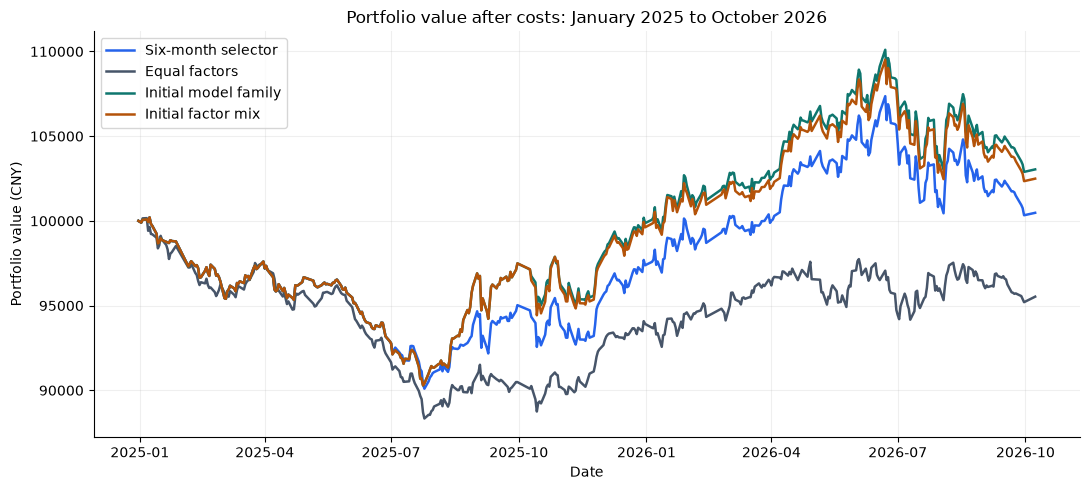

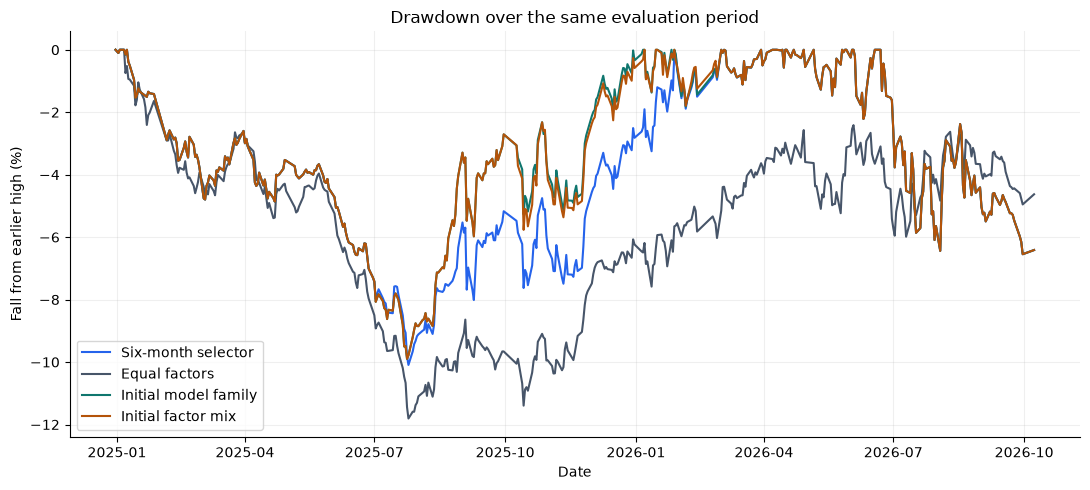

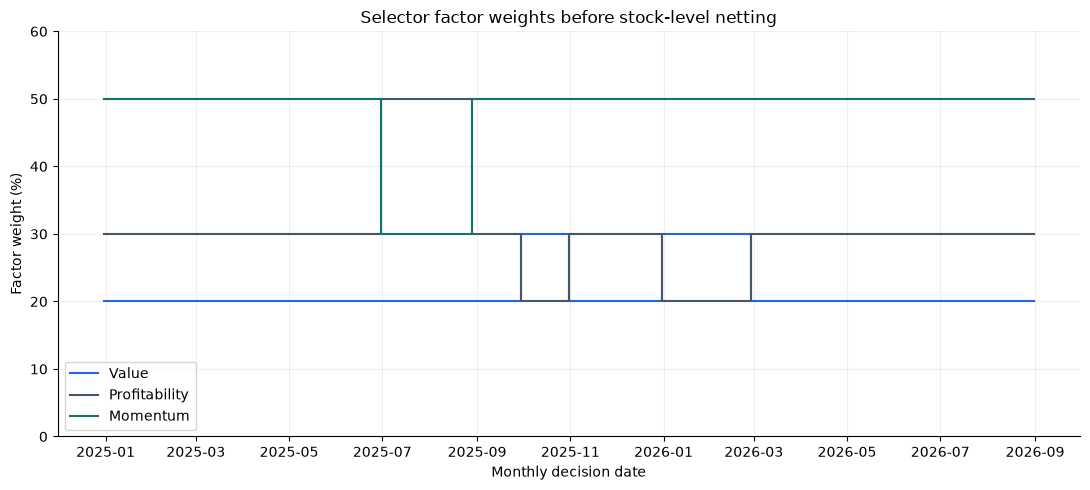

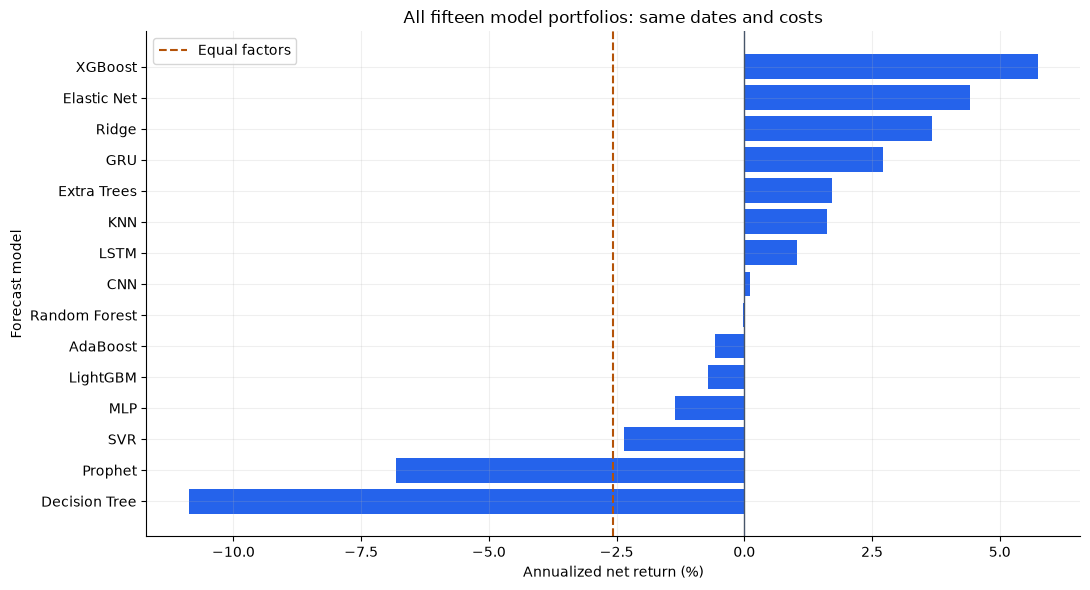

In [34]:
PLOT_COLORS = ['#2563eb','#475569','#0f766e','#b45309']
PLOT_SIZE = (11,5)
chart_names = comparison_names[:4]
figure,axis = plt.subplots(figsize=PLOT_SIZE)
for i,name in enumerate(chart_names):
    axis.plot(portfolio_values.index,portfolio_values[name],label=name,color=PLOT_COLORS[i],linewidth=1.8)
axis.set_title('Portfolio value after costs: January 2025 to October 2026')
axis.set_xlabel('Date')
axis.set_ylabel('Portfolio value (CNY)')
axis.legend()
figure.tight_layout()
figure.savefig(RESULTS/'portfolio_values.png',dpi=160)
plt.show()
figure,axis = plt.subplots(figsize=PLOT_SIZE)
for i,name in enumerate(chart_names):
    series = portfolio_values[name]
    axis.plot(series.index,(series/series.cummax()-1)*100,label=name,color=PLOT_COLORS[i],linewidth=1.5)
axis.set_title('Drawdown over the same evaluation period')
axis.set_xlabel('Date')
axis.set_ylabel('Fall from earlier high (%)')
axis.legend()
figure.tight_layout()
figure.savefig(RESULTS/'drawdowns.png',dpi=160)
plt.show()
figure,axis = plt.subplots(figsize=PLOT_SIZE)
weight_plot = factor_weight_table.loc[factor_weight_table.seed.eq(42)&factor_weight_table.strategy.eq('Six-month selector')].set_index('signal')[FACTORS]
for i,factor in enumerate(FACTORS):
    axis.step(weight_plot.index,weight_plot[factor]*100,label=factor,where='post',color=PLOT_COLORS[i])
axis.set_title('Selector factor weights before stock-level netting')
axis.set_xlabel('Monthly decision date')
axis.set_ylabel('Factor weight (%)')
axis.set_ylim(0,60)
axis.legend()
figure.tight_layout()
figure.savefig(RESULTS/'factor_weights.png',dpi=160)
plt.show()
figure,axis = plt.subplots(figsize=(11,6))
model_plot = performance.set_index('strategy').loc[LEARNED_MODELS,'annual_return'].sort_values()
axis.barh(model_plot.index,model_plot.values,color='#2563eb')
axis.axvline(0,color='#475569',linewidth=1)
axis.axvline(main_results.loc['Equal factors','annual_return'],color='#b45309',linestyle='--',label='Equal factors')
axis.set_title('All fifteen model portfolios: same dates and costs')
axis.set_xlabel('Annualized net return (%)')
axis.set_ylabel('Forecast model')
axis.legend()
figure.tight_layout()
figure.savefig(RESULTS/'all_models.png',dpi=160)
plt.show()


What did we find?

Our main question is whether using forecasts to change factor weights helps after costs. The recorded six-month selection rule earned 2.83 percentage points more annual return than equal factors in this sample. The original Prophet-selected strategy returned -6.82% a year. The two selection rules therefore need to be read separately. The six-month selector earned less than keeping the first model family and less than keeping its first factor mix. Changing model families did not improve on those controls in this sample. We found that the selection rule, initial factor mix and trading costs matter when we turn forecasts into a portfolio. We do not conclude that machine learning always improves investing. These findings describe the selected A-share group, the stated data and 21 completed monthly periods.

Keeping the first selected model family returned 1.71% a year. Keeping its first factor mix returned 1.41%. The selector's differences were -1.44 and -1.14 percentage points. These controls keep the company baskets changing each month. They separate a changing family from a changing factor mix.

The selector's mean absolute forecast error was 2.55 percentage points. It predicted the factor direction correctly in 50.79% of the 63 forecasts and chose the best factor in 42.86% of the 21 months. Forecast accuracy and net portfolio return answer different questions.

The original M6 rule selected Prophet before the evaluation, using the validation best-factor hit rate. Its later annual return remains -6.82%. XGBoost had the highest individual model return at 5.74%, but this later ranking was not used to choose the original model. We report both facts.

The financial data may contain later revisions. The reporting delay does not prove that every figure matches what investors saw at that time. The list was chosen from companies available when we built the sample. Short positions assume that shares could be borrowed. These results describe this selected group and our stated costs. They are not proof of a live trading return or of performance across the whole Chinese market.

References

Shu, Yizhan, and John M. Mulvey. Dynamic Factor Allocation Leveraging Regime-Switching Signals. The Journal of Portfolio Management, vol. 51, no. 3, 2025, pp. 50–72. doi:10.3905/jpm.2024.1.649.

Politis, Dimitris N., and Joseph P. Romano. The Stationary Bootstrap. Journal of the American Statistical Association, vol. 89, no. 428, 1994, pp. 1303–13. doi:10.1080/01621459.1994.10476870.

Bailey, David H., et al. The Probability of Backtest Overfitting. Manuscript, revised 27 February 2015.

Bailey, David H., and Marcos López de Prado. The Deflated Sharpe Ratio: Correcting for Selection Bias, Backtest Overfitting and Non-Normality. Manuscript, 31 July 2014.

Scikit-learn Developers. Cross-Validation: Evaluating Estimator Performance. Scikit-learn User Guide, section on time series.